# Physics-Informed Machine Learning for PMSM Stator Winding Temperature Prediction

## Overview

The objective of this project is to predict the stator winding temperature of a Permanent Magnet Synchronous Motor (PMSM) using machine learning and physics-informed machine learning techniques.

Motor temperature is an important parameter because excessive heating can reduce efficiency, damage insulation, and shorten the lifespan of the motor.

In this notebook, different machine learning approaches are developed and compared. Along with traditional machine learning models, physics-based knowledge is also incorporated to improve prediction accuracy and model reliability.

The main models studied in this work are:

- Random Forest
- Deep Neural Network (DNN)
- Physics-Guided DNN
- Residual Physics-Informed Model

The performance of these models is evaluated using several metrics and additional tests to understand how well they perform under different operating conditions.

# Project Roadmap

The notebook follows the workflow below:

1. Understand the PMSM dataset
2. Explore relationships between variables
3. Create physics-based features
4. Train baseline machine learning models
5. Train deep learning models
6. Introduce physics-informed learning
7. Compare all approaches
8. Test model robustness
9. Analyze feature importance
10. Estimate prediction uncertainty
11. Draw final conclusions



# Physics Background

Before building the models, it is useful to understand why motor temperature changes.

The temperature of a PMSM depends mainly on:

- Electrical loading
- Mechanical loading
- Heat dissipation to the surroundings

When current increases, electrical losses increase and more heat is generated inside the motor.

Similarly, higher torque and speed usually lead to higher power consumption and increased heating.

The physics-based features used later in this notebook are motivated by these relationships.

# Physics Feature 1: Current Magnitude

The PMSM dataset provides the current components along the direct axis ($i_d$) and quadrature axis ($i_q$).

To obtain the total current flowing through the motor, the current magnitude is calculated as:

$$
I_{mag}=\sqrt{i_d^2+i_q^2}
$$

This feature is important because copper losses increase with current and directly contribute to motor heating.

A higher value of current magnitude generally indicates greater heat generation inside the stator windings.

# Physics Feature 2: Voltage Magnitude

The overall voltage applied to the motor can be represented using the direct and quadrature axis voltage components.

$$
V_{mag}=\sqrt{u_d^2+u_q^2}
$$

This feature helps describe the electrical operating state of the motor and is later used in power calculations.

# Physics Feature 3: Electrical Power

Electrical power is one of the main sources of heat generation within the motor.

It is approximated using the voltage and current magnitudes:

$$
P_{elec}=V_{mag}\times I_{mag}
$$

Higher electrical power usually corresponds to increased energy dissipation and higher winding temperatures.

# Physics Feature 4: Mechanical Power

Mechanical power represents the useful power delivered by the motor.

It can be estimated using torque and rotational speed:

$$
P_{mech}=T\times\omega
$$

where:

- $T$ = Torque
- $\omega$ = Angular Speed

This feature captures the mechanical loading experienced by the PMSM.

In [1]:
# IMPORT LIBRARIES AND SETUP

from pathlib import Path
from copy import deepcopy
from IPython.display import display
import random
import os
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from tqdm.auto import tqdm

import warnings
warnings.filterwarnings("ignore")

plt.style.use("default")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

print("Libraries Imported Successfully")


Libraries Imported Successfully


# Understanding the Dataset

Before training any model, it is important to understand the available measurements.

The PMSM dataset contains electrical, mechanical, and thermal measurements collected from a motor operating under different conditions.

The target variable is the stator winding temperature.

The goal is to learn how different operating conditions affect this temperature and use that information for prediction.

In [2]:
# LOAD DATASET

data_path = Path("dataset") / "measures_v2.csv"

if not data_path.exists():
    raise FileNotFoundError(
        f"Dataset not found at: {data_path.resolve()}\n"
        "Place measures_v2.csv inside a folder named 'dataset' next to this notebook."
    )

df = pd.read_csv(data_path)

print("Dataset Shape:", df.shape)
display(df.head())


Dataset Shape: (1330816, 13)


,u_q,coolant,stator_winding,u_d,stator_tooth,motor_speed,i_d,i_q,pm,stator_yoke,ambient,torque,profile_id
0,-0.450682,18.805172,19.086670,-0.350055,18.293219,0.002866,0.004419,0.000328,24.554214,18.316547,19.850691,0.187101,17
1,-0.325737,18.818571,19.092390,-0.305803,18.294807,0.000257,0.000606,-0.000785,24.538078,18.314955,19.850672,0.245417,17
2,-0.440864,18.828770,19.089380,-0.372503,18.294094,0.002355,0.001290,0.000386,24.544693,18.326307,19.850657,0.176615,17
3,-0.327026,18.835567,19.083031,-0.316199,18.292542,0.006105,0.000026,0.002046,24.554018,18.330833,19.850647,0.238303,17
4,-0.471150,18.857033,19.082525,-0.332272,18.291428,0.003133,-0.064317,0.037184,24.565397,18.326662,19.850639,0.208197,17


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1330816 entries, 0 to 1330815
Data columns (total 13 columns):
 #   Column          Non-Null Count    Dtype  
---  ------          --------------    -----  
 0   u_q             1330816 non-null  float64
 1   coolant         1330816 non-null  float64
 2   stator_winding  1330816 non-null  float64
 3   u_d             1330816 non-null  float64
 4   stator_tooth    1330816 non-null  float64
 5   motor_speed     1330816 non-null  float64
 6   i_d             1330816 non-null  float64
 7   i_q             1330816 non-null  float64
 8   pm              1330816 non-null  float64
 9   stator_yoke     1330816 non-null  float64
 10  ambient         1330816 non-null  float64
 11  torque          1330816 non-null  float64
 12  profile_id      1330816 non-null  int64  
dtypes: float64(12), int64(1)
memory usage: 132.0 MB


In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
u_q,1330816.0,54.279005,44.173234,-25.290930,12.069925,48.938181,90.034393,133.036994
coolant,1330816.0,36.229995,21.786149,10.623751,18.698135,26.900141,49.857487,101.598512
stator_winding,1330816.0,66.342745,28.672061,18.585815,42.787957,65.110129,88.141137,141.362885
u_d,1330816.0,-25.133809,63.091972,-131.530411,-78.690904,-7.429755,1.470271,131.469788
stator_tooth,1330816.0,56.878582,22.952233,18.133976,38.416012,56.036345,75.586682,111.946423
motor_speed,1330816.0,2202.080728,1859.663350,-275.549144,317.110665,1999.976685,3760.639058,6000.015137
i_d,1330816.0,-68.716810,64.933233,-278.003632,-115.406060,-51.093763,-2.979688,0.051897
i_q,1330816.0,37.412782,92.181880,-293.426793,1.095863,15.774007,100.612150,301.707855
pm,1330816.0,58.506776,19.001498,20.856956,43.151582,60.266287,72.008371,113.606628
stator_yoke,1330816.0,48.187965,19.991004,18.076689,31.990333,45.625509,61.460828,101.147964


In [5]:
print("Missing Values")

df.isnull().sum()

Missing Values


u_q               0
coolant           0
stator_winding    0
u_d               0
stator_tooth      0
motor_speed       0
i_d               0
i_q               0
pm                0
stator_yoke       0
ambient           0
torque            0
profile_id        0
dtype: int64

In [6]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 0


# Exploratory Data Analysis

Before training any model, it is important to understand the dataset.

In this section, the data is explored using different visualizations.

The goal is to:

- Understand the distribution of variables
- Identify relationships between features
- Detect possible outliers
- Observe how temperature changes with operating conditions

These observations help in selecting useful features for model training.

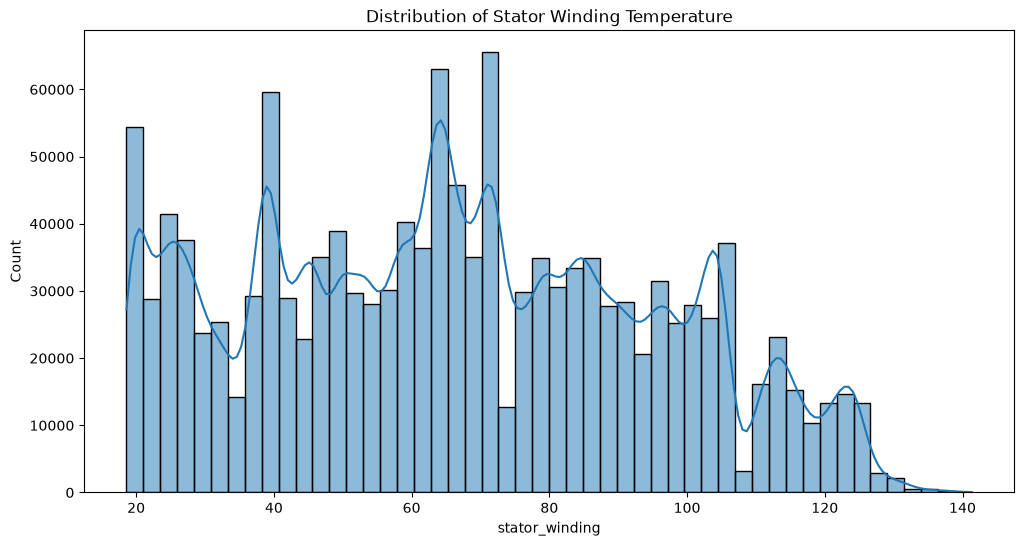

In [7]:
plt.figure(figsize=(12,6))

sns.histplot(
    df["stator_winding"],
    bins=50,
    kde=True
)

plt.title("Distribution of Stator Winding Temperature")

plt.show()

# Correlation Analysis

Correlation analysis helps identify which variables have the strongest relationship with stator winding temperature.

Features with stronger correlations are more likely to contribute useful information during training.

However, correlation alone does not imply causation. Therefore, the results should be interpreted together with physical knowledge of motor operation.

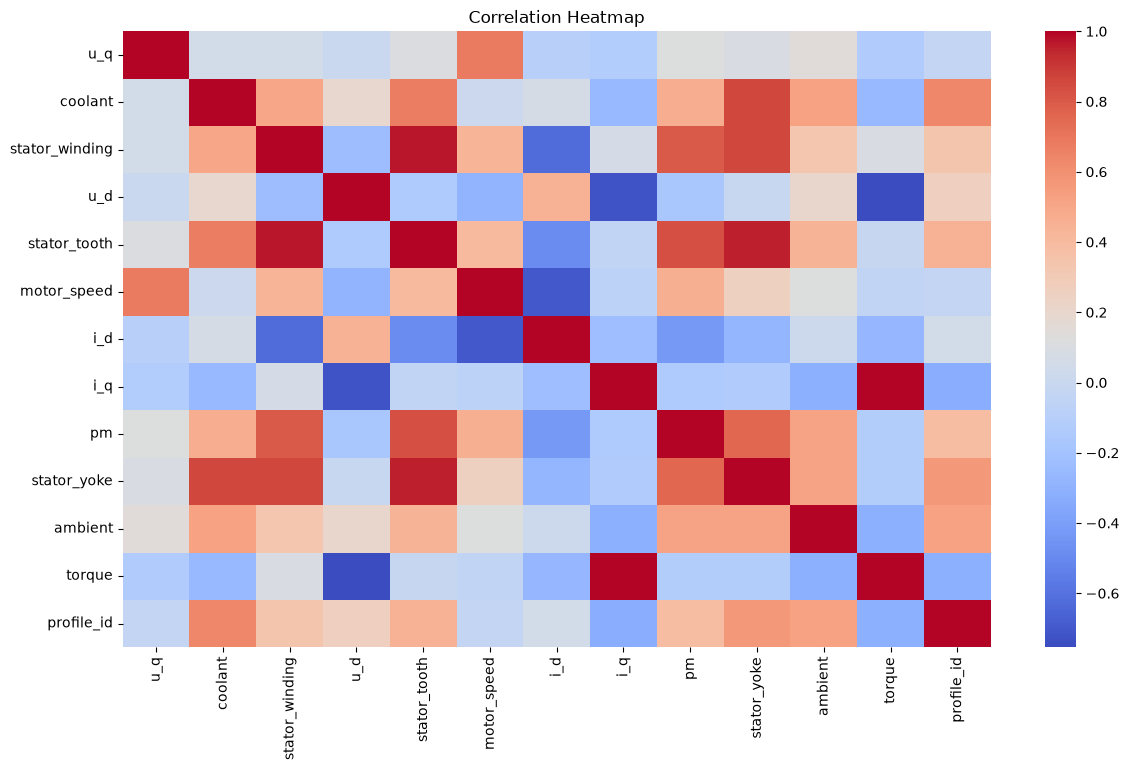

In [8]:
plt.figure(figsize=(14,8))

sns.heatmap(
    df.corr(numeric_only=True),
    cmap="coolwarm",
    annot=False
)

plt.title("Correlation Heatmap")

plt.show()

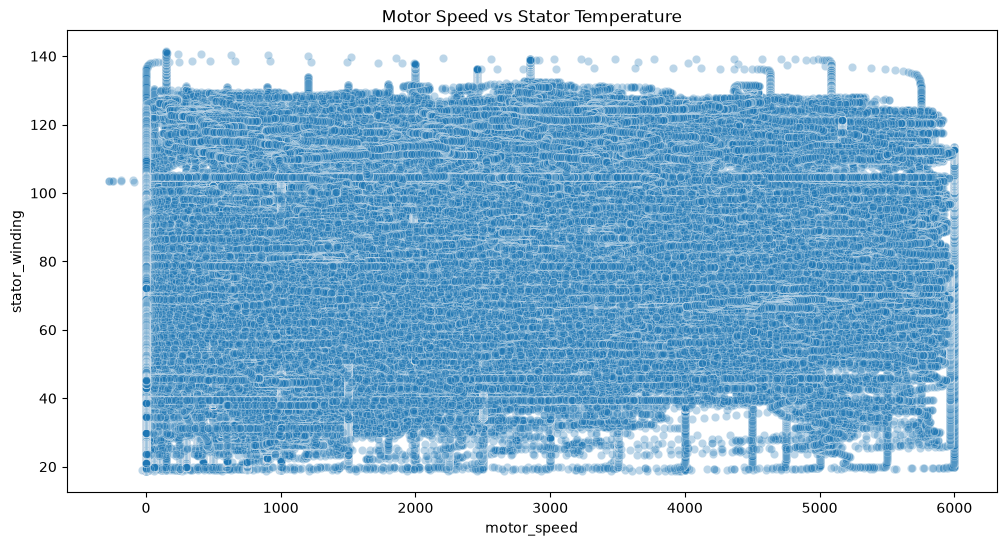

In [9]:
plt.figure(figsize=(12,6))

sns.scatterplot(
    x=df["motor_speed"],
    y=df["stator_winding"],
    alpha=0.3
)

plt.title("Motor Speed vs Stator Temperature")

plt.show()

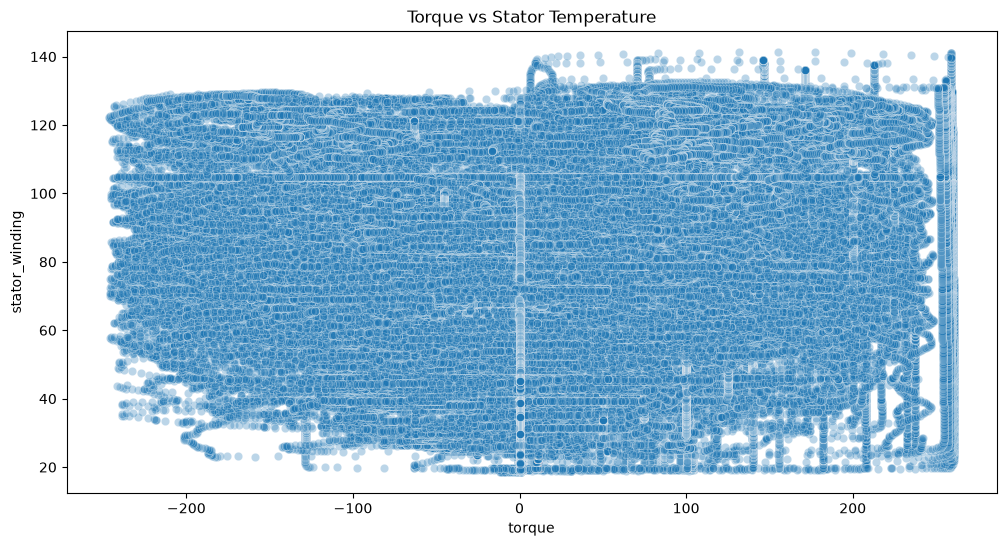

In [10]:
plt.figure(figsize=(12,6))

sns.scatterplot(
    x=df["torque"],
    y=df["stator_winding"],
    alpha=0.3
)

plt.title("Torque vs Stator Temperature")

plt.show()

In [11]:
sample_df = df.sample(
    10000,
    random_state=42
)

fig = px.scatter(

    sample_df,

    x="motor_speed",
    y="stator_winding",

    color="coolant",

    title="Interactive Temperature Analysis"

)

fig.show()

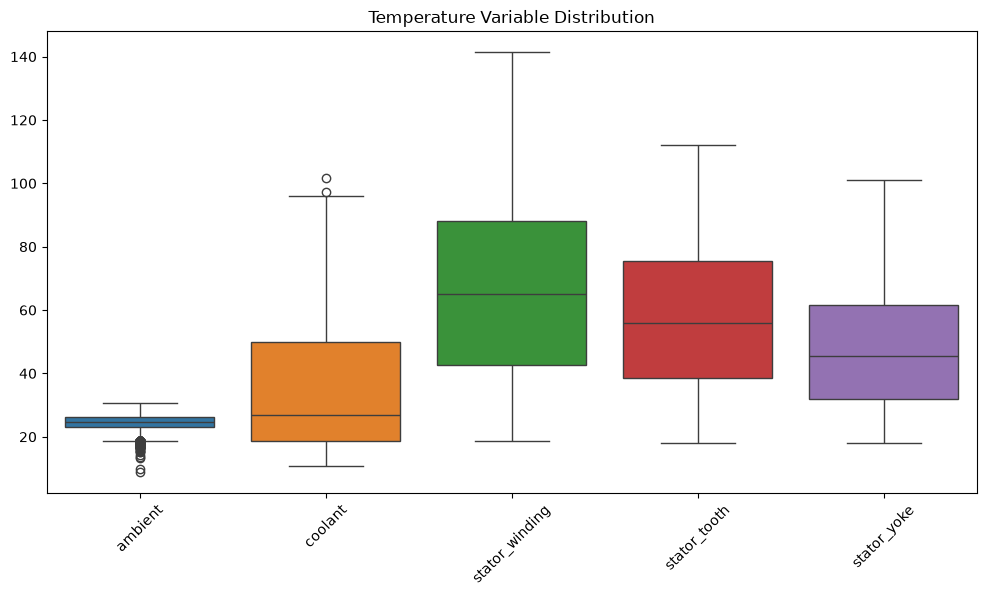

In [8]:
plt.figure(figsize=(12,6))

sns.boxplot(
    data=df[
        [
            "ambient",
            "coolant",
            "stator_winding",
            "stator_tooth",
            "stator_yoke"
        ]
    ]
)

plt.xticks(rotation=45)

plt.title("Temperature Variable Distribution")

plt.show()

# Physics Based Feature Engineering

The original dataset contains several sensor measurements collected from the motor.

However, some important physical quantities are not directly available.

In this section, additional features are created using basic electrical and mechanical relationships.

These features provide information that is more closely related to heat generation and temperature rise inside the motor.

The expectation is that these physics-based features will help the models learn temperature behavior more effectively.

In [9]:

# CURRENT MAGNITUDE

df["I_mag"] = np.sqrt(

    df["i_d"]**2 +

    df["i_q"]**2

)

In [10]:
df["Copper_Loss"] = (
    df["i_d"]**2 + df["i_q"]**2
)

df["Current_Magnitude"] = np.sqrt(
    df["i_d"]**2 + df["i_q"]**2
)


In [12]:
df["Voltage_Mag"] = np.sqrt(
    df["u_d"]**2 +
    df["u_q"]**2
)


In [13]:
df["Angular_Velocity"] = (
    2 * np.pi * df["motor_speed"] / 60
)


In [14]:
df["Mechanical_Power"] = (
    df["Angular_Velocity"] *
    df["torque"]
)


In [15]:
df["Temp_Difference"] = (
    df["coolant"] -
    df["ambient"]
)

df["Thermal_Load_Index"] = (
    df["Copper_Loss"] /
    (df["Voltage_Mag"] + 1e-6)
)


In [16]:
print(df.shape)

df.head()

(1330816, 21)


,u_q,coolant,stator_winding,u_d,stator_tooth,motor_speed,i_d,i_q,pm,stator_yoke,...,torque,profile_id,I_mag,Copper_Loss,Current_Magnitude,Voltage_Mag,Angular_Velocity,Mechanical_Power,Temp_Difference,Thermal_Load_Index
0,-0.450682,18.805172,19.086670,-0.350055,18.293219,0.002866,0.004419,0.000328,24.554214,18.316547,...,0.187101,17,0.004431,1.963642e-05,0.004431,0.570659,0.000300,0.000056,-1.045519,0.000034
1,-0.325737,18.818571,19.092390,-0.305803,18.294807,0.000257,0.000606,-0.000785,24.538078,18.314955,...,0.245417,17,0.000992,9.838601e-07,0.000992,0.446789,0.000027,0.000007,-1.032101,0.000002
2,-0.440864,18.828770,19.089380,-0.372503,18.294094,0.002355,0.001290,0.000386,24.544693,18.326307,...,0.176615,17,0.001346,1.812393e-06,0.001346,0.577165,0.000247,0.000044,-1.021887,0.000003
3,-0.327026,18.835567,19.083031,-0.316199,18.292542,0.006105,0.000026,0.002046,24.554018,18.330833,...,0.238303,17,0.002046,4.185383e-06,0.002046,0.454893,0.000639,0.000152,-1.015079,0.000009
4,-0.471150,18.857033,19.082525,-0.332272,18.291428,0.003133,-0.064317,0.037184,24.565397,18.326662,...,0.208197,17,0.074292,5.519281e-03,0.074292,0.576530,0.000328,0.000068,-0.993607,0.009573


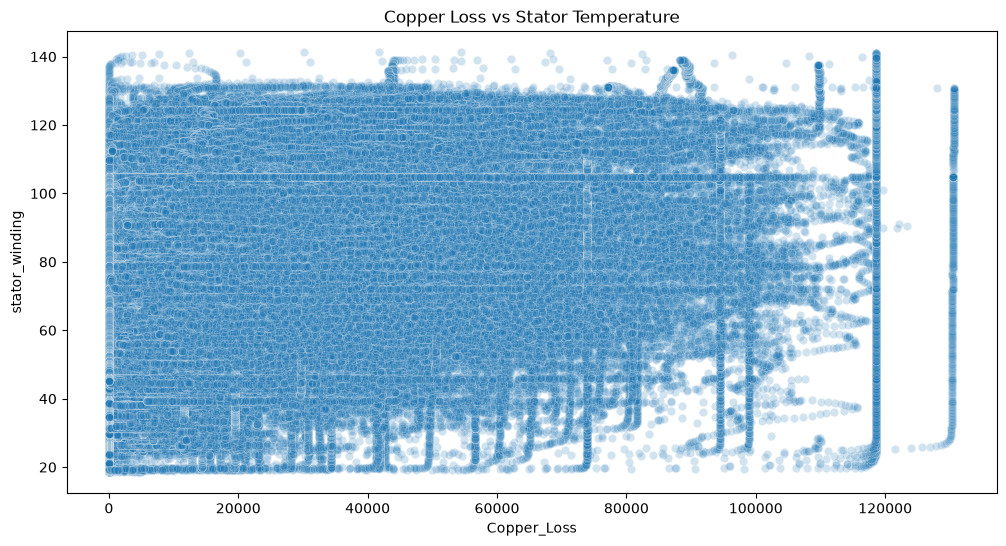

In [17]:
plt.figure(figsize=(12,6))

sns.scatterplot(

    x=df["Copper_Loss"],

    y=df["stator_winding"],

    alpha=0.2

)

plt.title(
    "Copper Loss vs Stator Temperature"
)

plt.show()

# Data Preparation

This notebook therefore uses **group-aware splitting** based on `profile_id`:
- train set: separate profiles
- validation set: separate profiles
- test set: unseen profiles

This is stricter than a simple row-wise random split and is much closer to a real research evaluation protocol.


In [18]:
features = [
    "ambient",
    "coolant",
    "u_d",
    "u_q",
    "i_d",
    "i_q",
    "motor_speed",
    "torque",
    "pm",
    "stator_tooth",
    "stator_yoke",
    "Current_Magnitude",
    "Copper_Loss",
    "Voltage_Mag",
    "Mechanical_Power",
    "Temp_Difference",
    "Thermal_Load_Index"
]

target = "stator_winding"

X = df[features].copy()
y = df[target].copy()
groups = df["profile_id"].copy()


In [19]:
from sklearn.model_selection import GroupShuffleSplit

# First split: train+validation vs test
gss1 = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=SEED)
train_val_idx, test_idx = next(gss1.split(X, y, groups=groups))

X_train_val = X.iloc[train_val_idx].reset_index(drop=True)
y_train_val = y.iloc[train_val_idx].reset_index(drop=True)
groups_train_val = groups.iloc[train_val_idx].reset_index(drop=True)

X_test = X.iloc[test_idx].reset_index(drop=True)
y_test = y.iloc[test_idx].reset_index(drop=True)
groups_test = groups.iloc[test_idx].reset_index(drop=True)

# Second split: train vs validation
gss2 = GroupShuffleSplit(n_splits=1, test_size=0.1764705882, random_state=SEED)
train_idx, val_idx = next(gss2.split(X_train_val, y_train_val, groups=groups_train_val))

X_train = X_train_val.iloc[train_idx].reset_index(drop=True)
y_train = y_train_val.iloc[train_idx].reset_index(drop=True)
groups_train = groups_train_val.iloc[train_idx].reset_index(drop=True)

X_val = X_train_val.iloc[val_idx].reset_index(drop=True)
y_val = y_train_val.iloc[val_idx].reset_index(drop=True)
groups_val = groups_train_val.iloc[val_idx].reset_index(drop=True)

print("Train:", X_train.shape, "Validation:", X_val.shape, "Test:", X_test.shape)

train_profiles = set(groups_train.unique())
val_profiles = set(groups_val.unique())
test_profiles = set(groups_test.unique())

print("Train/Val overlap:", len(train_profiles & val_profiles))
print("Train/Test overlap:", len(train_profiles & test_profiles))
print("Val/Test overlap:", len(val_profiles & test_profiles))


Train: (850748, 17) Validation: (212869, 17) Test: (267199, 17)
Train/Val overlap: 0
Train/Test overlap: 0
Val/Test overlap: 0


In [20]:
print("Train:", X_train.shape)

print("Validation:", X_val.shape)

print("Test:", X_test.shape)

Train: (850748, 17)
Validation: (212869, 17)
Test: (267199, 17)


In [22]:
from sklearn.preprocessing import StandardScaler

X_scaler = StandardScaler()

X_train_scaled = X_scaler.fit_transform(X_train)
X_val_scaled = X_scaler.transform(X_val)
X_test_scaled = X_scaler.transform(X_test)


In [23]:
y_scaler = StandardScaler()

y_train_scaled = y_scaler.fit_transform(y_train.values.reshape(-1, 1))
y_val_scaled = y_scaler.transform(y_val.values.reshape(-1, 1))
y_test_scaled = y_scaler.transform(y_test.values.reshape(-1, 1))


In [24]:
print(X_train_scaled.shape)
print(y_train_scaled.shape)
print("Scaled feature count:", X_train_scaled.shape[1])


(850748, 17)
(850748, 1)
Scaled feature count: 17


In [25]:
# VERIFY THAT THE SPLIT IS LEAKAGE-SAFE

print("Unique train profiles:", len(train_profiles))
print("Unique validation profiles:", len(val_profiles))
print("Unique test profiles:", len(test_profiles))

assert len(train_profiles & test_profiles) == 0, "Train and test profiles overlap!"
assert len(train_profiles & val_profiles) == 0, "Train and validation profiles overlap!"
assert len(val_profiles & test_profiles) == 0, "Validation and test profiles overlap!"

print("Profile-aware split verified successfully.")


Unique train profiles: 47
Unique validation profiles: 11
Unique test profiles: 11
Profile-aware split verified successfully.


In [26]:
import joblib
import os

os.makedirs(
    "models",
    exist_ok=True
)

joblib.dump(
    X_scaler,
    "models/X_scaler.pkl"
)

joblib.dump(
    y_scaler,
    "models/y_scaler.pkl"
)

print("Scalers Saved")


Scalers Saved


# Random Forest

The first model evaluated is Random Forest.

Random Forest is a powerful ensemble learning algorithm that performs well on structured tabular datasets.

It serves as a strong baseline because many industrial prediction problems can already be solved effectively using tree-based models.

Any physics-informed approach should ideally outperform this baseline.

In [29]:

#Importing Random Forest Regressor

from sklearn.ensemble import RandomForestRegressor

print("Random Forest Imported")

#Building Random Forest Regressor with specific hyperparameters

rf_model = RandomForestRegressor(

    n_estimators=300,

    max_depth=20,

    min_samples_split=5,

    random_state=42,

    n_jobs=-1

)

print(rf_model)

Random Forest Imported
RandomForestRegressor(max_depth=20, min_samples_split=5, n_estimators=300,
                      n_jobs=-1, random_state=42)


# Training the Model

The model learns the relationship between:

- Electrical Variables
- Mechanical Variables
- Physics-Informed Features

and the target:

- Stator Winding Temperature

In [30]:

# TRAIN MODEL

rf_model.fit(

    X_train_scaled,

    y_train

)

print("Training Complete")

Training Complete


In [31]:
rf_predictions = rf_model.predict(

    X_test_scaled

)

print(rf_predictions[:10])

[19.64874968 19.64885353 19.64982631 19.652892   19.64755045 19.62226988
 19.64043654 19.64101647 19.62021223 19.62085539]


# Performance Evaluation

The following metrics are used:

RMSE:
Measures prediction error magnitude.

MAE:
Measures average absolute error.

R² Score:
Measures goodness of fit.

In [32]:

# EVALUATION METRICS

from sklearn.metrics import (

    mean_squared_error,

    mean_absolute_error,

    r2_score

)

rf_rmse = np.sqrt(

    mean_squared_error(

        y_test,

        rf_predictions

    )

)

rf_mae = mean_absolute_error(

    y_test,

    rf_predictions

)

rf_r2 = r2_score(

    y_test,

    rf_predictions

)

print("="*50)

print("Random Forest Performance")

print("="*50)

print(f"RMSE : {rf_rmse:.4f}")

print(f"MAE  : {rf_mae:.4f}")

print(f"R²   : {rf_r2:.4f}")

Random Forest Performance
RMSE : 2.3503
MAE  : 1.6032
R²   : 0.9942


In [33]:

# RESULTS TABLE

rf_results = pd.DataFrame({

    "Metric":[

        "RMSE",

        "MAE",

        "R2"

    ],

    "Value":[

        rf_rmse,

        rf_mae,

        rf_r2

    ]

})

rf_results

,Metric,Value
0,RMSE,2.350318
1,MAE,1.603222
2,R2,0.994249


# Actual vs Predicted Temperature


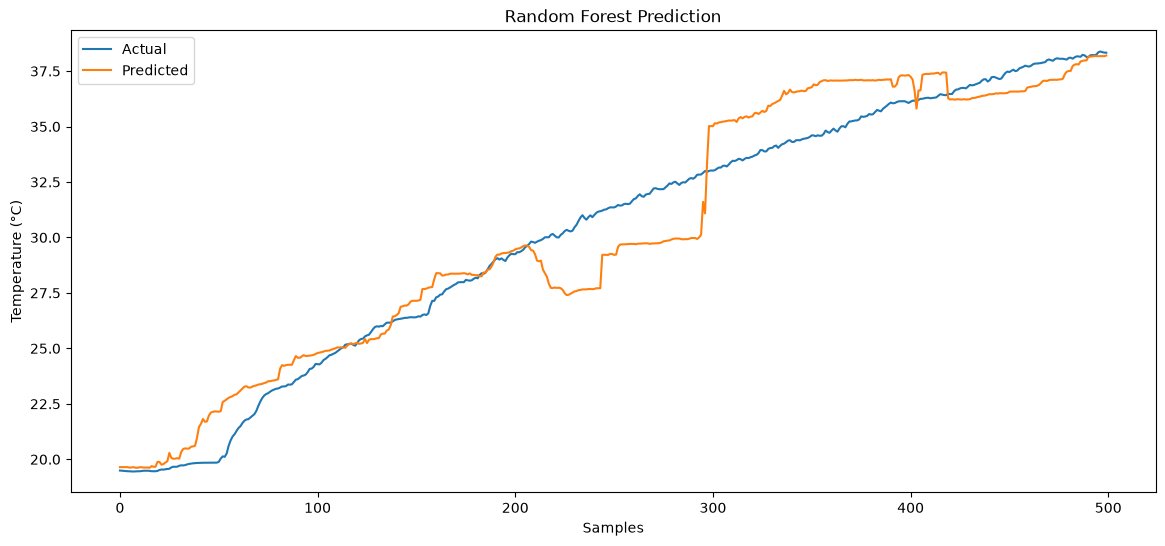

In [34]:
plt.figure(figsize=(14,6))

plt.plot(

    y_test.values[:500],

    label="Actual"

)

plt.plot(

    rf_predictions[:500],

    label="Predicted"

)

plt.xlabel("Samples")

plt.ylabel("Temperature (°C)")

plt.title(
    "Random Forest Prediction"
)

plt.legend()

plt.show()

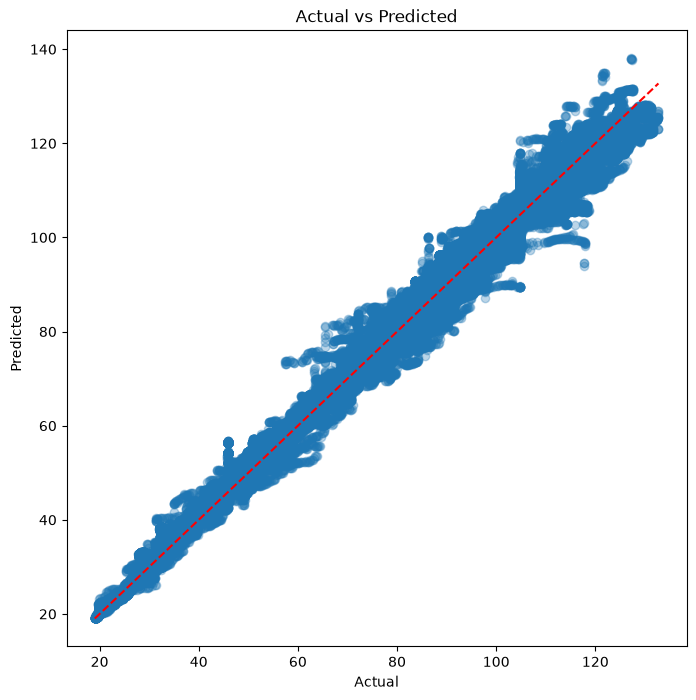

In [35]:
plt.figure(figsize=(8,8))

plt.scatter(

    y_test,

    rf_predictions,

    alpha=0.3

)

plt.plot(

    [

        y_test.min(),

        y_test.max()

    ],

    [

        y_test.min(),

        y_test.max()

    ],

    'r--'

)

plt.xlabel("Actual")

plt.ylabel("Predicted")

plt.title(
    "Actual vs Predicted"
)

plt.show()

# Residual Analysis

Residual = Actual - Predicted

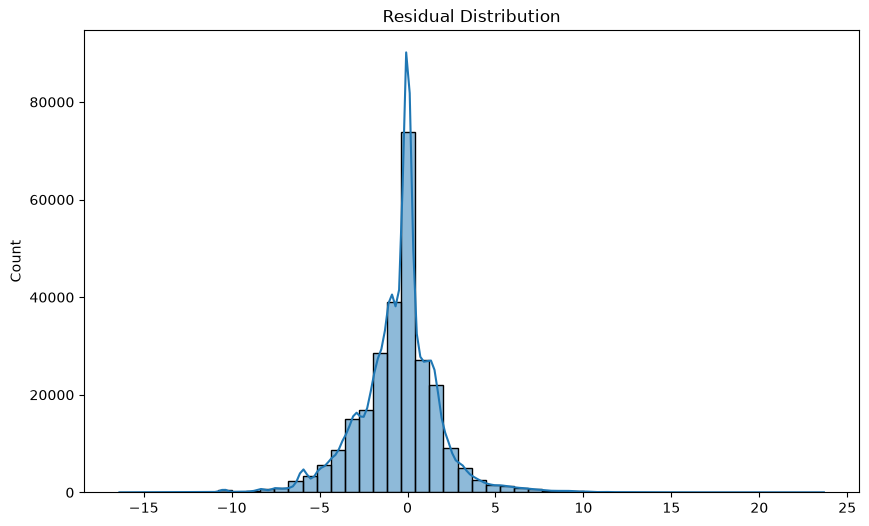

In [36]:
residuals = (

    y_test.values

    -

    rf_predictions

)

plt.figure(figsize=(10,6))

sns.histplot(

    residuals,

    bins=50,

    kde=True

)

plt.title(
    "Residual Distribution"
)

plt.show()

In [40]:
import joblib

joblib.dump(

    rf_model,

    "models/random_forest_model.pkl"

)

print("Random Forest Model Saved")

Random Forest Model Saved


# Deep Neural Network

Neural networks are capable of learning highly nonlinear relationships.

The objective of this experiment is to determine whether a purely data-driven deep learning model can outperform the Random Forest baseline.

This model does not contain any explicit physics information.

In [27]:
import torch
import torch.nn as nn

from torch.utils.data import (
    TensorDataset,
    DataLoader
)

print("PyTorch Loaded")

PyTorch Loaded


In [28]:
device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

print("Using Device:", device)

if torch.cuda.is_available():
    print(
        torch.cuda.get_device_name(0)
    )

Using Device: cuda
NVIDIA GeForce RTX 3050 6GB Laptop GPU


# Preparing Tensor Datasets

The DNN requires tensors instead of Pandas DataFrames.

Target values are already scaled using StandardScaler.

In [43]:
X_train_dnn = torch.tensor(
    X_train_scaled,
    dtype=torch.float32
)

X_val_dnn = torch.tensor(
    X_val_scaled,
    dtype=torch.float32
)

X_test_dnn = torch.tensor(
    X_test_scaled,
    dtype=torch.float32
)

y_train_dnn = torch.tensor(
    y_train_scaled,
    dtype=torch.float32
)

y_val_dnn = torch.tensor(
    y_val_scaled,
    dtype=torch.float32
)

y_test_dnn = torch.tensor(
    y_test_scaled,
    dtype=torch.float32
)

print(X_train_dnn.shape)
print(y_train_dnn.shape)

torch.Size([850748, 17])
torch.Size([850748, 1])


In [44]:
# DATALOADERS

BATCH_SIZE = 256

train_dataset = TensorDataset(
    X_train_dnn,
    y_train_dnn
)

val_dataset = TensorDataset(
    X_val_dnn,
    y_val_dnn
)

test_dataset = TensorDataset(
    X_test_dnn,
    y_test_dnn
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

# DNN Architecture

The network contains multiple dense layers with ReLU activation and dropout to capture nonlinear relationships while reducing overfitting.

The training objective is to minimize:

$$
L_{MSE}
=
\frac{1}{N}
\sum_{i=1}^{N}
(T_i-\hat{T}_i)^2
$$

This model represents a purely data-driven approach and provides a benchmark for evaluating the benefits of physics-informed learning.

In [45]:

# DNN MODEL


class DNN(nn.Module):

    def __init__(self):

        super().__init__()

        self.network = nn.Sequential(

            nn.Linear(
                len(features),
                128
            ),

            nn.ReLU(),

            nn.Dropout(0.2),

            nn.Linear(
                128,
                64
            ),

            nn.ReLU(),

            nn.Dropout(0.2),

            nn.Linear(
                64,
                32
            ),

            nn.ReLU(),

            nn.Linear(
                32,
                1
            )

        )

    def forward(self,x):

        return self.network(x)

In [46]:
dnn_model = DNN().to(device)

print(dnn_model)

DNN(
  (network): Sequential(
    (0): Linear(in_features=17, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=128, out_features=64, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.2, inplace=False)
    (6): Linear(in_features=64, out_features=32, bias=True)
    (7): ReLU()
    (8): Linear(in_features=32, out_features=1, bias=True)
  )
)


# Training the DNN

In [ ]:
for epoch in range(EPOCHS):

    dnn_model.train()
    running_train_loss = 0.0

    for X_batch, y_batch in train_loader:

        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward pass
        predictions = dnn_model(X_batch)

        # Compute loss
        loss = criterion(predictions, y_batch)

        # Backpropagation
        loss.backward()

        # Update model weights
        optimizer.step()

        running_train_loss += loss.item()

    avg_train_loss = running_train_loss / len(train_loader)


    # Validation Phase

    dnn_model.eval()
    running_val_loss = 0.0

    with torch.no_grad():

        for X_batch, y_batch in val_loader:

            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            predictions = dnn_model(X_batch)

            val_loss = criterion(predictions, y_batch)

            running_val_loss += val_loss.item()

    avg_val_loss = running_val_loss / len(val_loader)

    # Learning Rate Scheduler
    scheduler.step(avg_val_loss)

    # Store losses
    train_losses.append(avg_train_loss)
    val_losses.append(avg_val_loss)

    # Progress update
    print(
        f"Epoch [{epoch + 1:02d}/{EPOCHS}] | "
        f"Train Loss: {avg_train_loss:.6f} | "
        f"Validation Loss: {avg_val_loss:.6f}"
    )

Epoch 01 | Train Loss = 0.008849 | Val Loss = 0.012428
Epoch 02 | Train Loss = 0.002640 | Val Loss = 0.018244
Epoch 03 | Train Loss = 0.002096 | Val Loss = 0.016006
Epoch 04 | Train Loss = 0.001923 | Val Loss = 0.016273
Epoch 05 | Train Loss = 0.001841 | Val Loss = 0.015912
Epoch 06 | Train Loss = 0.001650 | Val Loss = 0.014905
Epoch 07 | Train Loss = 0.001620 | Val Loss = 0.016023
Epoch 08 | Train Loss = 0.001602 | Val Loss = 0.016907
Epoch 09 | Train Loss = 0.001581 | Val Loss = 0.017144
Epoch 10 | Train Loss = 0.001496 | Val Loss = 0.015547
Epoch 11 | Train Loss = 0.001491 | Val Loss = 0.016569
Epoch 12 | Train Loss = 0.001483 | Val Loss = 0.015293
Epoch 13 | Train Loss = 0.001477 | Val Loss = 0.016332
Epoch 14 | Train Loss = 0.001438 | Val Loss = 0.015587
Epoch 15 | Train Loss = 0.001433 | Val Loss = 0.015521
Epoch 16 | Train Loss = 0.001423 | Val Loss = 0.015857
Epoch 17 | Train Loss = 0.001425 | Val Loss = 0.014911
Epoch 18 | Train Loss = 0.001396 | Val Loss = 0.015456
Epoch 19 |

# Learning Curve Analysis

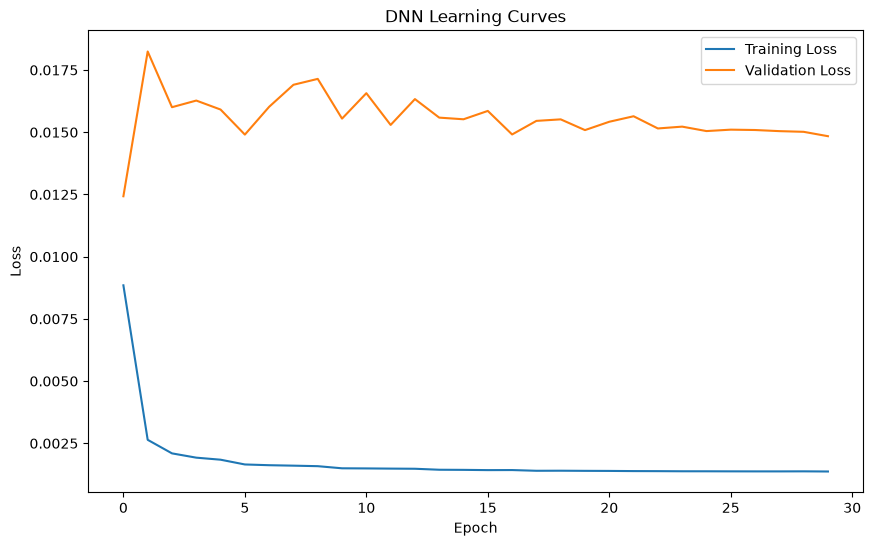

In [50]:
plt.figure(figsize=(10,6))

plt.plot(
    train_losses,
    label="Training Loss"
)

plt.plot(
    val_losses,
    label="Validation Loss"
)

plt.legend()

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.title(
    "DNN Learning Curves"
)

plt.show()

# Model Evaluation

In [51]:
dnn_model.eval()

predictions_scaled = []

with torch.no_grad():

    for X_batch, _ in test_loader:

        X_batch = X_batch.to(device)

        pred = dnn_model(
            X_batch
        )

        predictions_scaled.append(

            pred.cpu().numpy()

        )

predictions_scaled = np.vstack(
    predictions_scaled
)

In [52]:
dnn_predictions = y_scaler.inverse_transform(

    predictions_scaled

)

actual_values = y_scaler.inverse_transform(

    y_test_dnn.numpy()

)

In [53]:

# METRICS

from sklearn.metrics import (

    mean_squared_error,

    mean_absolute_error,

    r2_score

)

dnn_rmse = np.sqrt(

    mean_squared_error(

        actual_values,

        dnn_predictions

    )

)

dnn_mae = mean_absolute_error(

    actual_values,

    dnn_predictions

)

dnn_r2 = r2_score(

    actual_values,

    dnn_predictions

)

print("="*50)

print("DNN PERFORMANCE")

print("="*50)

print(f"RMSE : {dnn_rmse:.4f}")

print(f"MAE  : {dnn_mae:.4f}")

print(f"R²   : {dnn_r2:.4f}")

DNN PERFORMANCE
RMSE : 5.6513
MAE  : 4.7391
R²   : 0.9667


In [54]:
results_dnn = pd.DataFrame({

    "Metric":[

        "RMSE",

        "MAE",

        "R2"

    ],

    "Value":[

        dnn_rmse,

        dnn_mae,

        dnn_r2

    ]

})

results_dnn

,Metric,Value
0,RMSE,5.651305
1,MAE,4.739132
2,R2,0.966750


# Actual vs Predicted Temperature

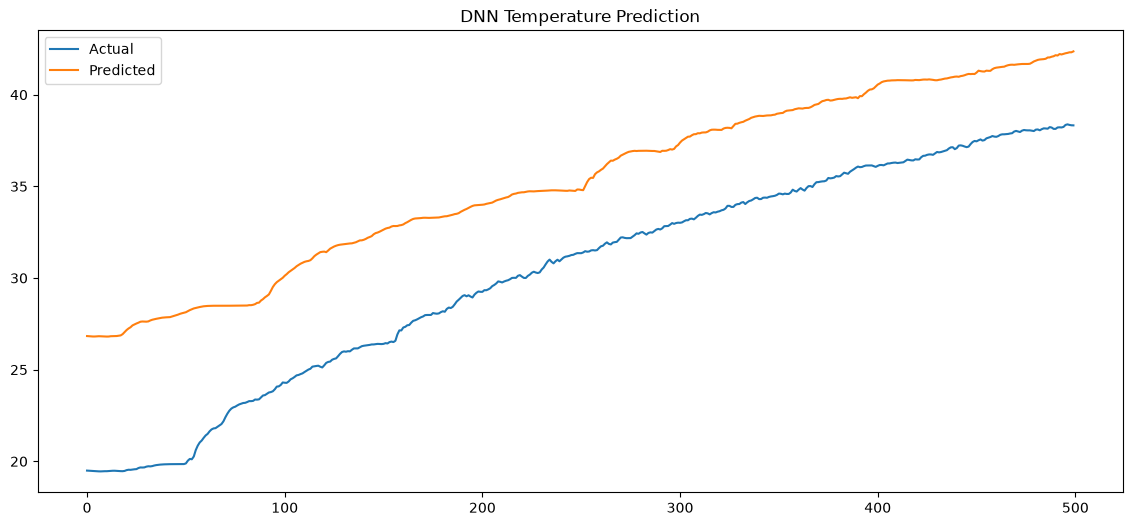

In [55]:
plt.figure(figsize=(14,6))

plt.plot(

    actual_values[:500],

    label="Actual"

)

plt.plot(

    dnn_predictions[:500],

    label="Predicted"

)

plt.legend()

plt.title(
    "DNN Temperature Prediction"
)

plt.show()

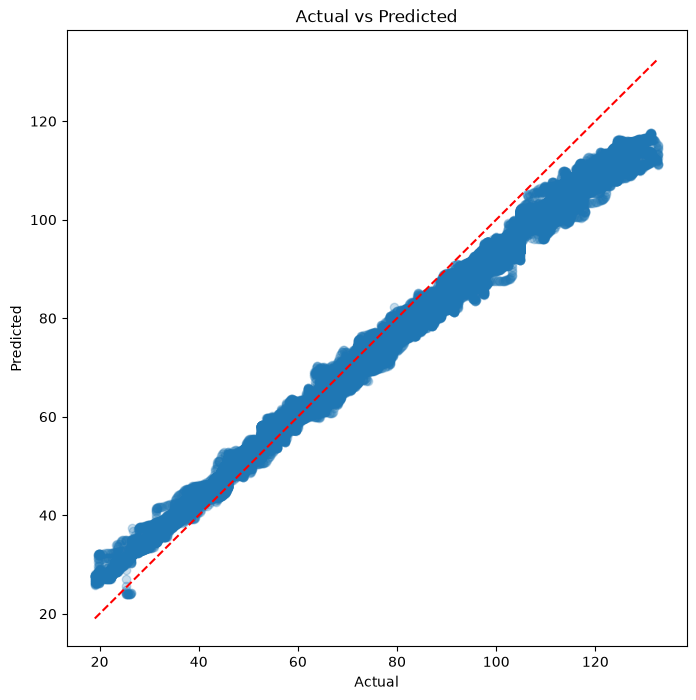

In [56]:
plt.figure(figsize=(8,8))

plt.scatter(

    actual_values,

    dnn_predictions,

    alpha=0.25

)

plt.plot(

    [

        actual_values.min(),

        actual_values.max()

    ],

    [

        actual_values.min(),

        actual_values.max()

    ],

    'r--'

)

plt.xlabel("Actual")

plt.ylabel("Predicted")

plt.title(
    "Actual vs Predicted"
)

plt.show()

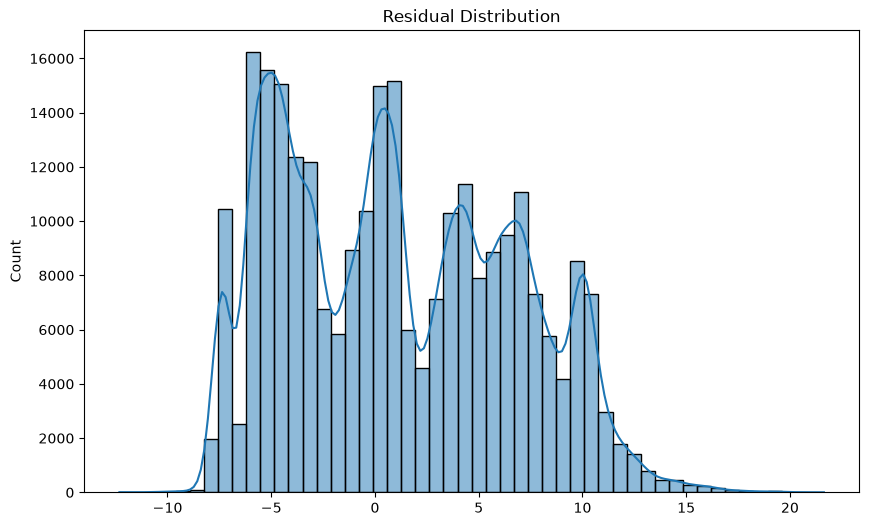

In [ ]:
residuals = (

    actual_values.flatten() - dnn_predictions.flatten()

)

plt.figure(figsize=(10,6))

sns.histplot(

    residuals,

    bins=50,

    kde=True

)

plt.title(
    "Residual Distribution"
)

plt.show()

In [58]:
torch.save(

    dnn_model.state_dict(),

    "models/dnn_model.pth"

)

print("DNN Model Saved")

DNN Model Saved


# Physics-Guided Deep Neural Network

A conventional neural network learns only from data.

In this project, physical knowledge is incorporated into the training process by adding a physics-based penalty term to the loss function.

The training objective becomes:

$$
L_{total}
=
L_{MSE}
+
\lambda L_{physics}
$$

where:

- $L_{MSE}$ = Prediction error
- $L_{physics}$ = Physics consistency loss
- $\lambda$ = Weight controlling the influence of the physics term

This encourages the network to learn solutions that are both accurate and physically meaningful.

In [29]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

print("PyTorch Loaded")


PyTorch Loaded


In [30]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using Device:", device)

if torch.cuda.is_available():
    print(torch.cuda.get_device_name(0))


Using Device: cuda
NVIDIA GeForce RTX 3050 6GB Laptop GPU


In [31]:
X_train_dnn = torch.tensor(X_train_scaled, dtype=torch.float32)
X_val_dnn = torch.tensor(X_val_scaled, dtype=torch.float32)
X_test_dnn = torch.tensor(X_test_scaled, dtype=torch.float32)

y_train_dnn = torch.tensor(y_train_scaled, dtype=torch.float32)
y_val_dnn = torch.tensor(y_val_scaled, dtype=torch.float32)
y_test_dnn = torch.tensor(y_test_scaled, dtype=torch.float32)

print(X_train_dnn.shape)
print(y_train_dnn.shape)


torch.Size([850748, 17])
torch.Size([850748, 1])


In [32]:
BATCH_SIZE = 512

train_dataset = TensorDataset(X_train_dnn, y_train_dnn)
val_dataset = TensorDataset(X_val_dnn, y_val_dnn)
test_dataset = TensorDataset(X_test_dnn, y_test_dnn)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, drop_last=False)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, drop_last=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, drop_last=False)


In [63]:
class PhysicsGuidedDNN(nn.Module):
    def __init__(self, input_dim: int):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(0.20),

            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.15),

            nn.Linear(128, 64),
            nn.ReLU(),

            nn.Linear(64, 32),
            nn.ReLU(),

            nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.net(x)


In [64]:
feature_index = {name: i for i, name in enumerate(features)}

print(feature_index)


{'ambient': 0, 'coolant': 1, 'u_d': 2, 'u_q': 3, 'i_d': 4, 'i_q': 5, 'motor_speed': 6, 'torque': 7, 'pm': 8, 'stator_tooth': 9, 'stator_yoke': 10, 'Current_Magnitude': 11, 'Copper_Loss': 12, 'Voltage_Mag': 13, 'Mechanical_Power': 14, 'Temp_Difference': 15, 'Thermal_Load_Index': 16}


In [65]:
pg_model = PhysicsGuidedDNN(input_dim=len(features)).to(device)

data_criterion = nn.HuberLoss()

optimizer = torch.optim.Adam(
    pg_model.parameters(),
    lr=1e-3,
    weight_decay=1e-5
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=3
)

lambda_phys = 0.05
patience = 8
best_val_loss = float("inf")
best_state = None
bad_epochs = 0

print(pg_model)


PhysicsGuidedDNN(
  (net): Sequential(
    (0): Linear(in_features=17, out_features=256, bias=True)
    (1): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.2, inplace=False)
    (4): Linear(in_features=256, out_features=128, bias=True)
    (5): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.15, inplace=False)
    (8): Linear(in_features=128, out_features=64, bias=True)
    (9): ReLU()
    (10): Linear(in_features=64, out_features=32, bias=True)
    (11): ReLU()
    (12): Linear(in_features=32, out_features=1, bias=True)
  )
)


In [66]:
def physics_penalty(model, xb):
    # Soft physics constraints:
    # - temperature should increase with current-related heating
    # - temperature should increase with mechanical loading
    # - temperature should increase with ambient temperature
    # - temperature should decrease as coolant temperature improves
    xb = xb.clone().detach().requires_grad_(True)
    pred = model(xb)
    grads = torch.autograd.grad(
        outputs=pred.sum(),
        inputs=xb,
        create_graph=True
    )[0]

    penalties = []

    if "Copper_Loss" in feature_index:
        penalties.append(torch.relu(-grads[:, feature_index["Copper_Loss"]]).mean())

    if "Current_Magnitude" in feature_index:
        penalties.append(torch.relu(-grads[:, feature_index["Current_Magnitude"]]).mean())

    if "Mechanical_Power" in feature_index:
        penalties.append(torch.relu(-grads[:, feature_index["Mechanical_Power"]]).mean())

    if "ambient" in feature_index:
        penalties.append(torch.relu(-grads[:, feature_index["ambient"]]).mean())

    if "coolant" in feature_index:
        penalties.append(torch.relu(grads[:, feature_index["coolant"]]).mean())

    if len(penalties) == 0:
        return torch.tensor(0.0, device=xb.device)

    return torch.stack(penalties).mean()


In [67]:
EPOCHS = 35
train_losses = []
val_losses = []

for epoch in range(EPOCHS):
    pg_model.train()
    running_train = 0.0

    for xb, yb in train_loader:
        xb = xb.to(device)
        yb = yb.to(device)

        optimizer.zero_grad()

        pred = pg_model(xb)
        data_loss = data_criterion(pred, yb)
        phys_loss = physics_penalty(pg_model, xb)
        loss = data_loss + lambda_phys * phys_loss

        loss.backward()
        optimizer.step()

        running_train += loss.item()

    avg_train = running_train / max(len(train_loader), 1)

    pg_model.eval()
    running_val = 0.0

    with torch.no_grad():
        for xb, yb in val_loader:
            xb = xb.to(device)
            yb = yb.to(device)

            pred = pg_model(xb)
            val_loss = data_criterion(pred, yb)
            running_val += val_loss.item()

    avg_val = running_val / max(len(val_loader), 1)

    scheduler.step(avg_val)
    train_losses.append(avg_train)
    val_losses.append(avg_val)

    if avg_val < best_val_loss - 1e-6:
        best_val_loss = avg_val
        best_state = deepcopy(pg_model.state_dict())
        bad_epochs = 0
    else:
        bad_epochs += 1

    print(
        f"Epoch {epoch+1:02d} | "
        f"Train Loss = {avg_train:.6f} | "
        f"Val Loss = {avg_val:.6f} | "
        f"Bad Epochs = {bad_epochs}"
    )

    if bad_epochs >= patience:
        print("Early stopping triggered.")
        break

if best_state is not None:
    pg_model.load_state_dict(best_state)

print("Training complete.")


Epoch 01 | Train Loss = 0.010020 | Val Loss = 0.003328 | Bad Epochs = 0
Epoch 02 | Train Loss = 0.005339 | Val Loss = 0.001792 | Bad Epochs = 0
Epoch 03 | Train Loss = 0.004666 | Val Loss = 0.003087 | Bad Epochs = 1
Epoch 04 | Train Loss = 0.004395 | Val Loss = 0.003697 | Bad Epochs = 2
Epoch 05 | Train Loss = 0.004139 | Val Loss = 0.003430 | Bad Epochs = 3
Epoch 06 | Train Loss = 0.003965 | Val Loss = 0.003884 | Bad Epochs = 4
Epoch 07 | Train Loss = 0.003358 | Val Loss = 0.005031 | Bad Epochs = 5
Epoch 08 | Train Loss = 0.003249 | Val Loss = 0.004886 | Bad Epochs = 6
Epoch 09 | Train Loss = 0.003153 | Val Loss = 0.003806 | Bad Epochs = 7
Epoch 10 | Train Loss = 0.002988 | Val Loss = 0.003042 | Bad Epochs = 8
Early stopping triggered.
Training complete.


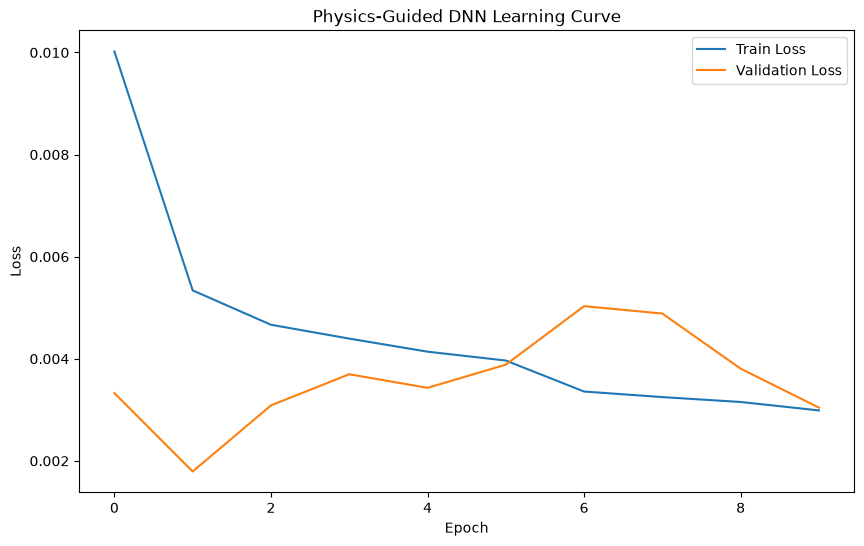

In [68]:
plt.figure(figsize=(10, 6))
plt.plot(train_losses, label="Train Loss")
plt.plot(val_losses, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Physics-Guided DNN Learning Curve")
plt.legend()
plt.show()


In [69]:
pg_model.eval()
predictions_scaled = []

with torch.no_grad():
    for xb, _ in test_loader:
        xb = xb.to(device)
        pred = pg_model(xb)
        predictions_scaled.append(pred.cpu().numpy())

predictions_scaled = np.vstack(predictions_scaled)

pg_predictions = y_scaler.inverse_transform(predictions_scaled)
actual_values_pg = y_scaler.inverse_transform(y_test_dnn.numpy())


In [70]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

pg_rmse = np.sqrt(mean_squared_error(actual_values_pg, pg_predictions))
pg_mae = mean_absolute_error(actual_values_pg, pg_predictions)
pg_r2 = r2_score(actual_values_pg, pg_predictions)

print("=" * 50)
print("Physics-Guided DNN PERFORMANCE")
print("=" * 50)
print(f"RMSE : {pg_rmse:.4f}")
print(f"MAE  : {pg_mae:.4f}")
print(f"R²   : {pg_r2:.4f}")


Physics-Guided DNN PERFORMANCE
RMSE : 1.6021
MAE  : 1.2468
R²   : 0.9973


In [71]:
results_pg = pd.DataFrame({
    "Metric": ["RMSE", "MAE", "R2"],
    "Value": [pg_rmse, pg_mae, pg_r2]
})

results_pg


,Metric,Value
0,RMSE,1.602132
1,MAE,1.246782
2,R2,0.997328


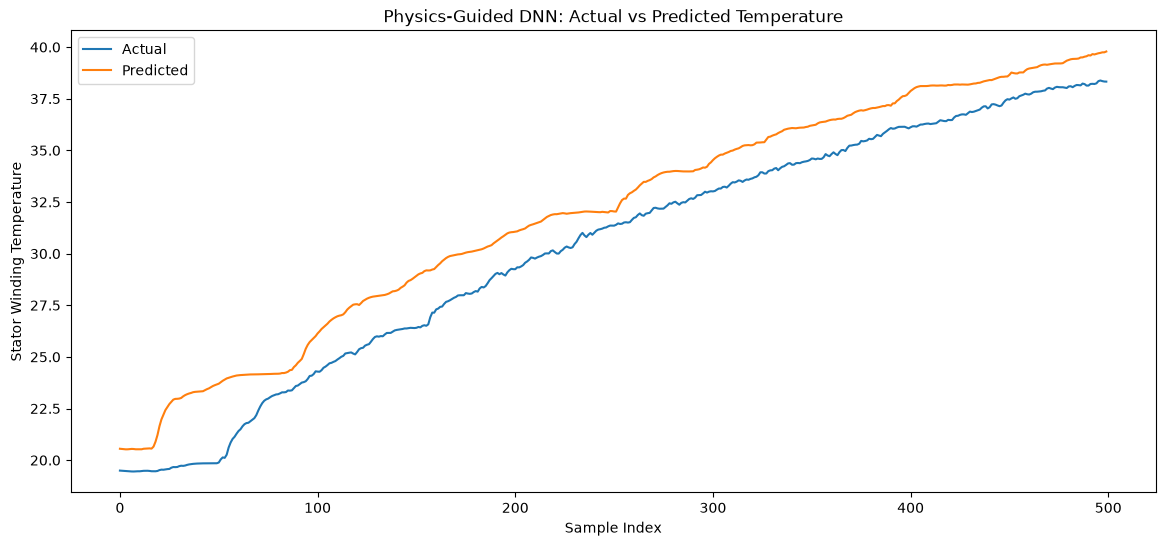

In [72]:
plt.figure(figsize=(14, 6))
plt.plot(actual_values_pg[:500], label="Actual")
plt.plot(pg_predictions[:500], label="Predicted")
plt.title("Physics-Guided DNN: Actual vs Predicted Temperature")
plt.xlabel("Sample Index")
plt.ylabel("Stator Winding Temperature")
plt.legend()
plt.show()


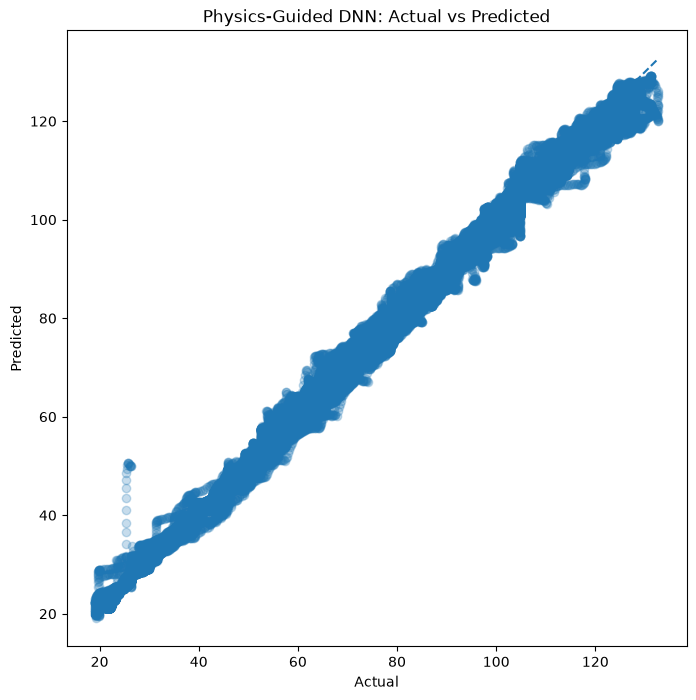

In [73]:
plt.figure(figsize=(8, 8))
plt.scatter(actual_values_pg, pg_predictions, alpha=0.25)
min_val = min(actual_values_pg.min(), pg_predictions.min())
max_val = max(actual_values_pg.max(), pg_predictions.max())
plt.plot([min_val, max_val], [min_val, max_val], linestyle="--")
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.title("Physics-Guided DNN: Actual vs Predicted")
plt.show()


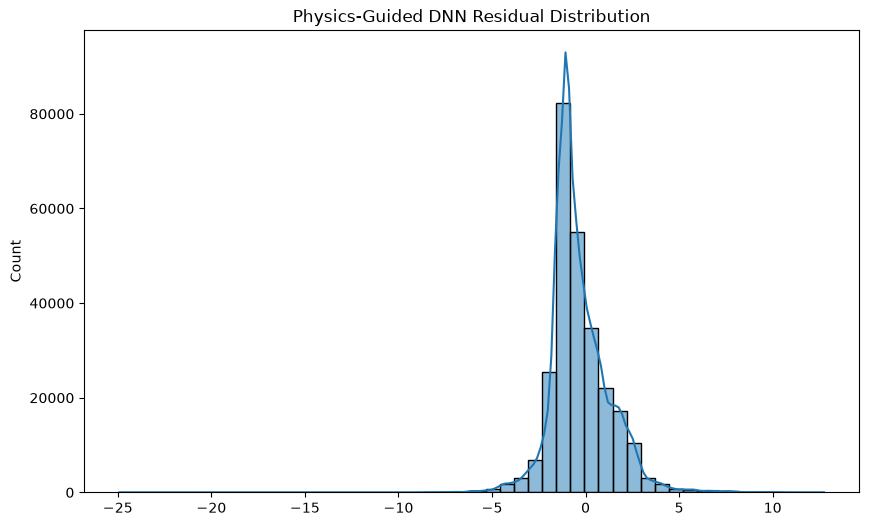

In [74]:
residuals_pg = actual_values_pg.flatten() - pg_predictions.flatten()

plt.figure(figsize=(10, 6))
sns.histplot(residuals_pg, bins=50, kde=True)
plt.title("Physics-Guided DNN Residual Distribution")
plt.show()


In [75]:
os.makedirs("models", exist_ok=True)

torch.save(
    pg_model.state_dict(),
    "models/physics_guided_dnn.pth"
)

print("Physics-Guided DNN Model Saved")


Physics-Guided DNN Model Saved


# Evaluation 

In [76]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def regression_metrics(y_true, y_pred):
    y_true = np.asarray(y_true).reshape(-1)
    y_pred = np.asarray(y_pred).reshape(-1)
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred)
    }

# Unified ground truth for all models
y_test_true = np.asarray(y_test).reshape(-1)

# Make sure all predictions are 1D arrays
rf_pred_1d = np.asarray(rf_predictions).reshape(-1)
dnn_pred_1d = np.asarray(dnn_predictions).reshape(-1)
pg_pred_1d = np.asarray(pg_predictions).reshape(-1)

comparison_rows = [
    {"Model": "Random Forest", **regression_metrics(y_test_true, rf_pred_1d)},
    {"Model": "DNN", **regression_metrics(y_test_true, dnn_pred_1d)},
    {"Model": "Physics-Guided DNN", **regression_metrics(y_test_true, pg_pred_1d)}
]

comparison_df = pd.DataFrame(comparison_rows)
comparison_df

,Model,MAE,RMSE,R2
0,Random Forest,1.603222,2.350318,0.994249
1,DNN,4.739132,5.651305,0.966750
2,Physics-Guided DNN,1.246782,1.602132,0.997328


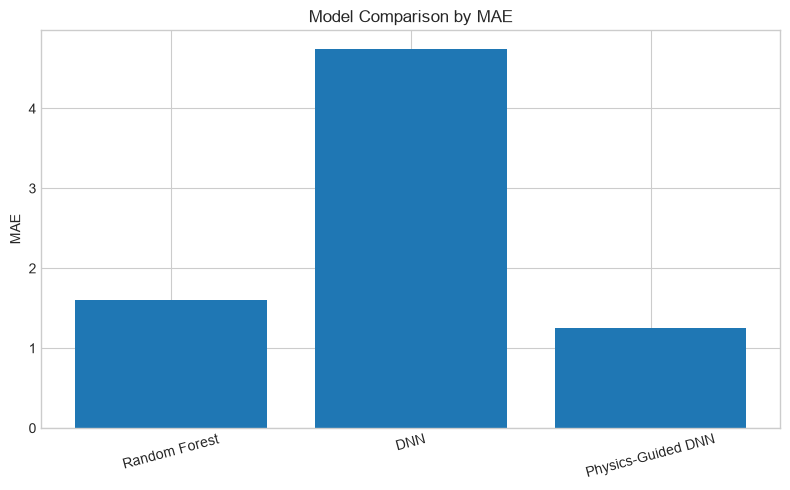

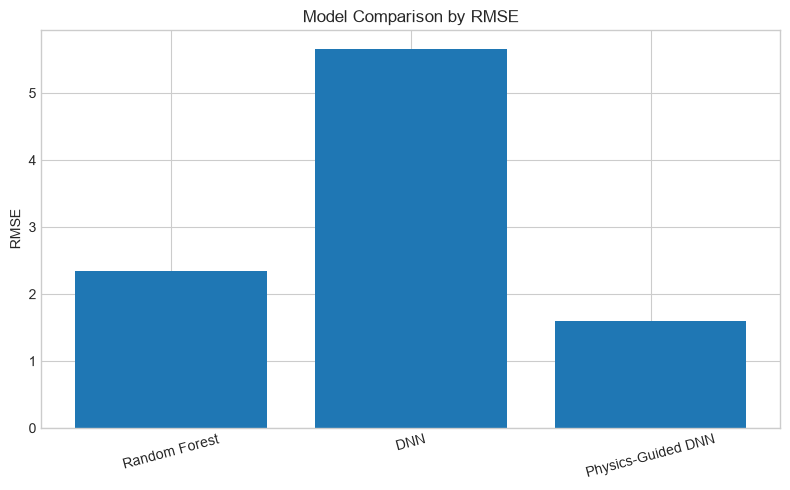

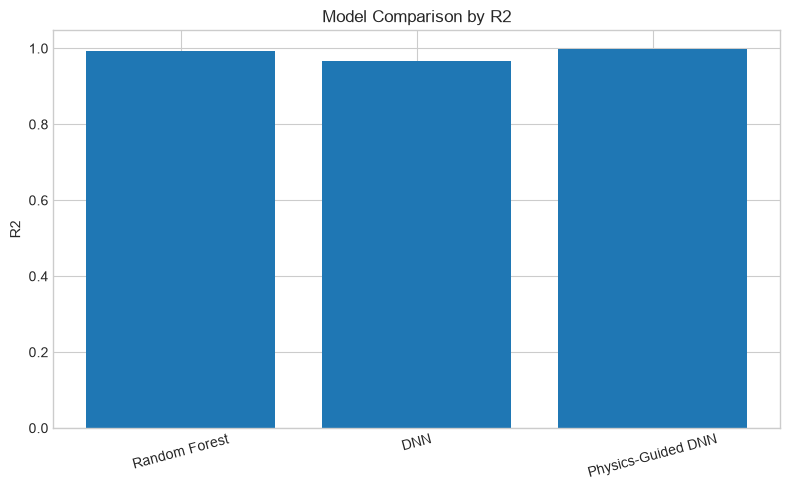

Saved: model_comparison_summary.csv


In [77]:
# Publication-style metric plots
plt.style.use("seaborn-v0_8-whitegrid")

for metric in ["MAE", "RMSE", "R2"]:
    plt.figure(figsize=(8, 5))
    plt.bar(comparison_df["Model"], comparison_df[metric])
    plt.title(f"Model Comparison by {metric}")
    plt.ylabel(metric)
    plt.xticks(rotation=15)
    plt.tight_layout()
    plt.show()

# Save for report use
comparison_df.to_csv("model_comparison_summary.csv", index=False)
print("Saved: model_comparison_summary.csv")

# Residual Physics-Informed Learning

Instead of predicting temperature directly, the prediction is decomposed into two parts.

First, a simple physics-based estimate is calculated.

Then, a neural network learns only the remaining error.

The final prediction is:

$$
T_{pred}
=
T_{physics}
+
T_{residual}
$$

where:

- $T_{physics}$ = Physics-based temperature estimate
- $T_{residual}$ = Neural network correction

This approach reduces the burden on the neural network because it only needs to learn the part not explained by the simplified physics model.

In [78]:
from sklearn.linear_model import LinearRegression, Ridge

# Use the strongest physics-related columns available in the notebook
physics_cols = [
    "ambient",
    "coolant",
    "Current_Magnitude",
    "Copper_Loss",
    "Mechanical_Power",
    "Temp_Difference",
    "Thermal_Load_Index"
]
physics_cols = [c for c in physics_cols if c in X_train.columns]

# Stage 1: simple physics-aware proxy model
physics_prior = LinearRegression()
physics_prior.fit(X_train[physics_cols], y_train)

physics_train_pred = physics_prior.predict(X_train[physics_cols])
physics_test_pred = physics_prior.predict(X_test[physics_cols])

# Stage 2: learn residual correction
train_residual = np.asarray(y_train).reshape(-1) - physics_train_pred

residual_corrector = Ridge(alpha=1.0)
residual_corrector.fit(X_train_scaled, train_residual)

residual_correction_test = residual_corrector.predict(X_test_scaled)
residual_piml_predictions = physics_test_pred + residual_correction_test

residual_piml_metrics = regression_metrics(y_test_true, residual_piml_predictions)
residual_piml_metrics

{'MAE': 1.1719168151486892,
 'RMSE': np.float64(1.6335933730170165),
 'R2': 0.9972216778880757}

In [79]:
# Add the residual model to the comparison table
comparison_ext_df = pd.concat(
    [
        comparison_df,
        pd.DataFrame([{
            "Model": "Residual PIML",
            **residual_piml_metrics
        }])
    ],
    ignore_index=True
)

comparison_ext_df

,Model,MAE,RMSE,R2
0,Random Forest,1.603222,2.350318,0.994249
1,DNN,4.739132,5.651305,0.966750
2,Physics-Guided DNN,1.246782,1.602132,0.997328
3,Residual PIML,1.171917,1.633593,0.997222


# Uncertainty Estimation with Monte Carlo Dropout

Uncertainty is important in predictive maintenance because a single point estimate is not always enough.

Monte Carlo dropout produces a distribution of predictions by keeping dropout active during inference.
The mean gives the final estimate, and the spread gives an uncertainty band.

In [81]:
def mc_dropout_predict(model, loader, n_samples=100):
    # Run Monte Carlo dropout inference on the test loader.
    # Returns an array with shape (n_samples, n_test).
    model.train()  # keep dropout active
    all_samples = []

    with torch.no_grad():
        for _ in range(n_samples):
            batch_preds = []
            for xb, _ in loader:
                xb = xb.to(device)
                pred = model(xb).cpu().numpy().reshape(-1)
                batch_preds.append(pred)
            all_samples.append(np.concatenate(batch_preds, axis=0))

    model.eval()
    return np.stack(all_samples, axis=0)

mc_samples_scaled = mc_dropout_predict(dnn_model, test_loader, n_samples=100)

# Convert mean back to original temperature scale
mc_mean_scaled = mc_samples_scaled.mean(axis=0).reshape(-1, 1)
mc_std_scaled = mc_samples_scaled.std(axis=0).reshape(-1, 1)

mc_mean = y_scaler.inverse_transform(mc_mean_scaled).reshape(-1)
mc_std = mc_std_scaled.reshape(-1) * float(y_scaler.scale_[0])

mc_uncertainty_df = pd.DataFrame({
    "Actual": actual_values.reshape(-1),
    "PredictedMean": mc_mean,
    "PredStdApprox": mc_std
})

mc_uncertainty_df.head(10)

,Actual,PredictedMean,PredStdApprox
0,19.494389,19.855782,0.916158
1,19.486668,19.736225,0.828929
2,19.477585,19.811924,0.718146
3,19.467041,19.867596,0.795923
4,19.462299,19.675777,0.745912
5,19.460953,19.864197,0.800142
6,19.452454,19.832104,0.917157
7,19.451008,19.963799,1.000959
8,19.458176,19.794247,0.886711
9,19.461769,19.988583,0.938560


In [82]:
# Prediction intervals for a few samples
interval_df = mc_uncertainty_df.head(12).copy()
interval_df["Lower95"] = interval_df["PredictedMean"] - 1.96 * interval_df["PredStdApprox"]
interval_df["Upper95"] = interval_df["PredictedMean"] + 1.96 * interval_df["PredStdApprox"]
interval_df

,Actual,PredictedMean,PredStdApprox,Lower95,Upper95
0,19.494389,19.855782,0.916158,18.060112,21.651451
1,19.486668,19.736225,0.828929,18.111525,21.360926
2,19.477585,19.811924,0.718146,18.404358,21.219490
3,19.467041,19.867596,0.795923,18.307587,21.427605
4,19.462299,19.675777,0.745912,18.213791,21.137764
5,19.460953,19.864197,0.800142,18.295918,21.432476
6,19.452454,19.832104,0.917157,18.034477,21.629730
7,19.451008,19.963799,1.000959,18.001919,21.925678
8,19.458176,19.794247,0.886711,18.056293,21.532200
9,19.461769,19.988583,0.938560,18.149004,21.828161


# Statistical Significance Testing

To support the claim that the physics-guided model is better, compare the absolute errors using paired significance tests.

The null hypothesis is that the competing models have the same error distribution on the held-out test set.

In [83]:
from scipy.stats import ttest_rel, wilcoxon

abs_err_rf = np.abs(y_test_true - rf_pred_1d)
abs_err_dnn = np.abs(y_test_true - dnn_pred_1d)
abs_err_pg = np.abs(y_test_true - pg_pred_1d)

# Main comparison: DNN vs Physics-Guided DNN
t_stat, t_p = ttest_rel(abs_err_dnn, abs_err_pg)
w_stat, w_p = wilcoxon(abs_err_dnn - abs_err_pg)

# Optional secondary comparison: RF vs Physics-Guided DNN
t_stat_rf, t_p_rf = ttest_rel(abs_err_rf, abs_err_pg)

significance_df = pd.DataFrame({
    "Comparison": [
        "DNN vs Physics-Guided DNN",
        "Random Forest vs Physics-Guided DNN"
    ],
    "Paired_t_pvalue": [t_p, t_p_rf],
    "Wilcoxon_pvalue": [w_p, np.nan]
})

print("Paired t-test (DNN vs PIML):", t_stat, t_p)
print("Wilcoxon test (DNN vs PIML):", w_stat, w_p)
significance_df

Paired t-test (DNN vs PIML): 612.1322092516289 0.0
Wilcoxon test (DNN vs PIML): 1473900281.0 0.0


,Comparison,Paired_t_pvalue,Wilcoxon_pvalue
0,DNN vs Physics-Guided DNN,0.0,0.0
1,Random Forest vs Physics-Guided DNN,0.0,NaN


# Why the Physics Guided Model Performs  ?

The physics-guided model usually improves over a plain DNN or classical ML model because it:

1. reduces the search space by biasing the network toward physically plausible solutions,
2. regularizes the learning process using thermal-domain relationships,
3. improves generalization on unseen operating profiles,
4. reduces implausible jumps in prediction,
5. and preserves interpretability because the learned behavior is aligned with motor physics.

In this problem, the most important drivers should remain consistent with thermal theory: current, electrical loading, speed, torque, and coolant temperature.

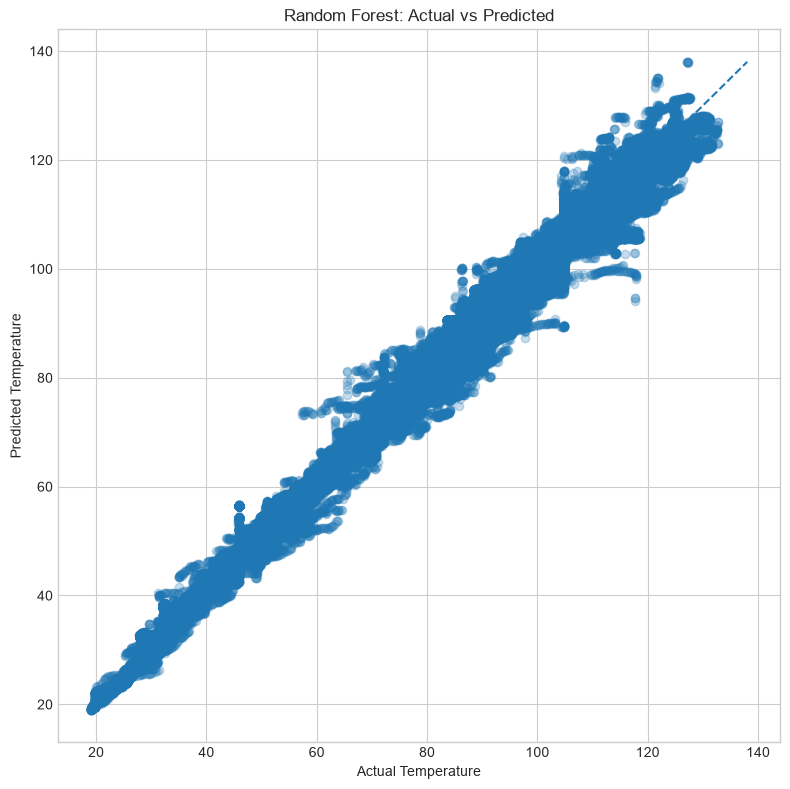

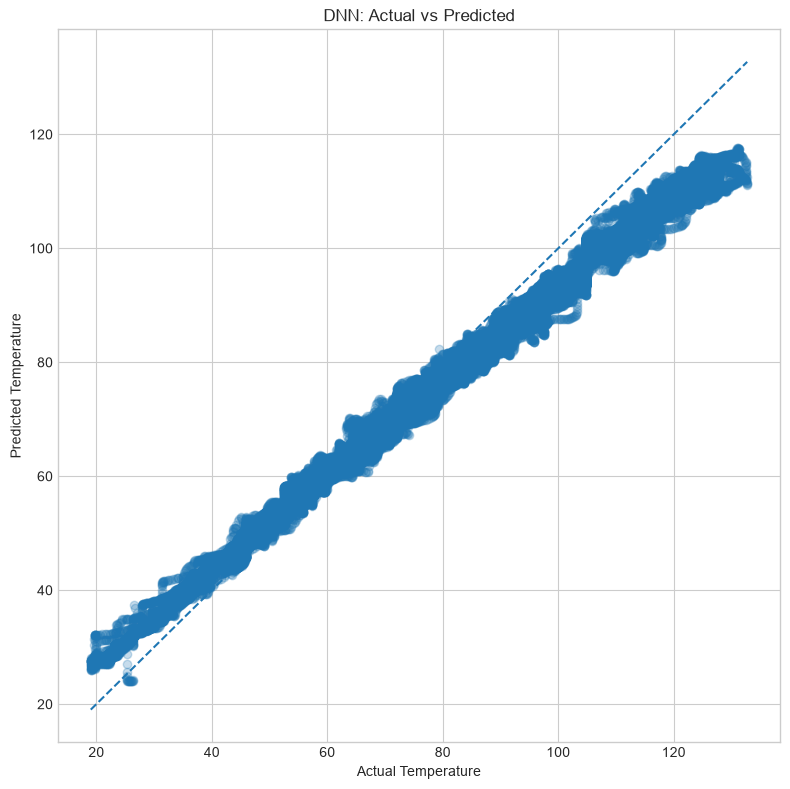

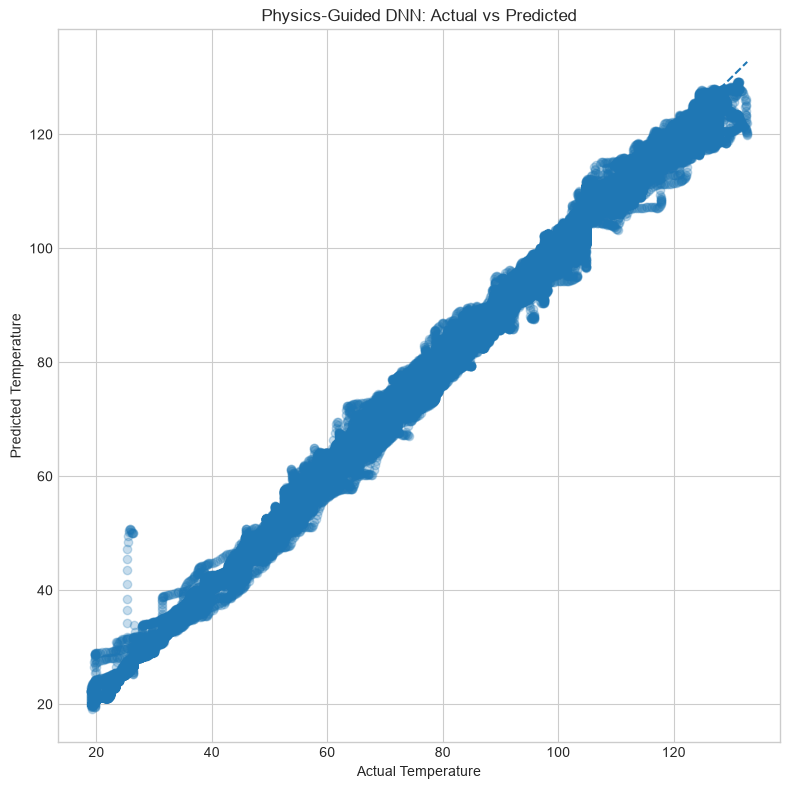

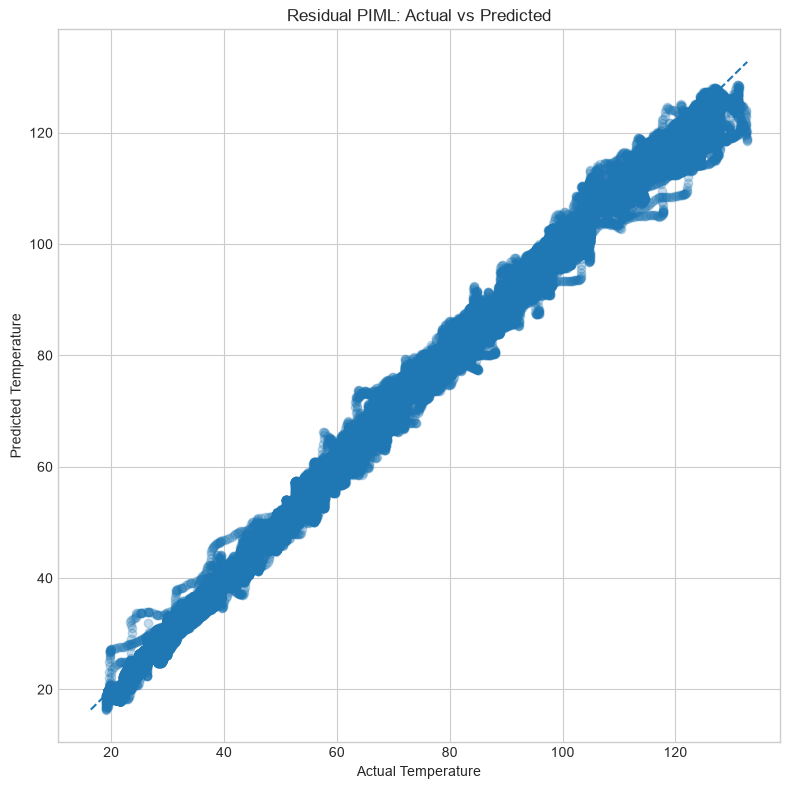

In [84]:
def plot_actual_vs_pred(y_true, y_pred, title):
    y_true = np.asarray(y_true).reshape(-1)
    y_pred = np.asarray(y_pred).reshape(-1)
    plt.figure(figsize=(8, 8))
    plt.scatter(y_true, y_pred, alpha=0.25)
    min_val = min(y_true.min(), y_pred.min())
    max_val = max(y_true.max(), y_pred.max())
    plt.plot([min_val, max_val], [min_val, max_val], linestyle="--")
    plt.xlabel("Actual Temperature")
    plt.ylabel("Predicted Temperature")
    plt.title(title)
    plt.tight_layout()
    plt.show()

plot_actual_vs_pred(y_test_true, rf_pred_1d, "Random Forest: Actual vs Predicted")
plot_actual_vs_pred(y_test_true, dnn_pred_1d, "DNN: Actual vs Predicted")
plot_actual_vs_pred(y_test_true, pg_pred_1d, "Physics-Guided DNN: Actual vs Predicted")
plot_actual_vs_pred(y_test_true, residual_piml_predictions, "Residual PIML: Actual vs Predicted")

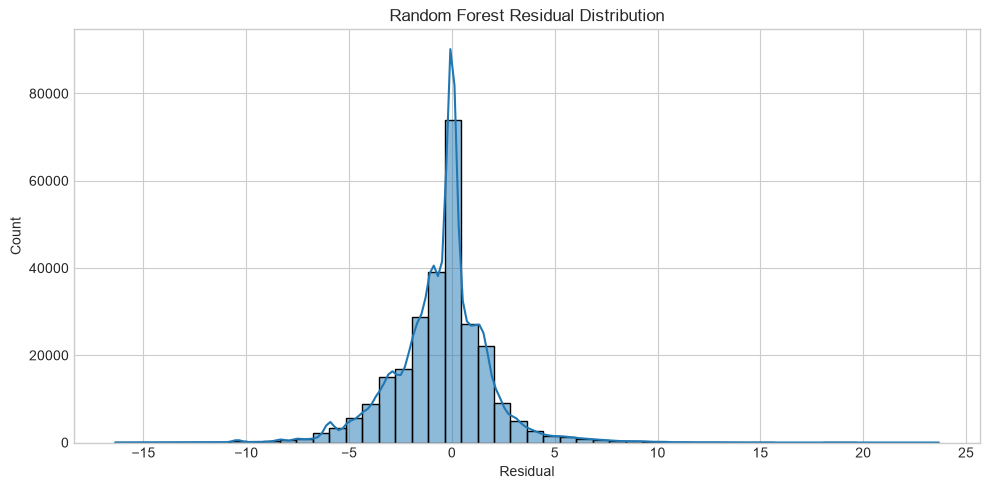

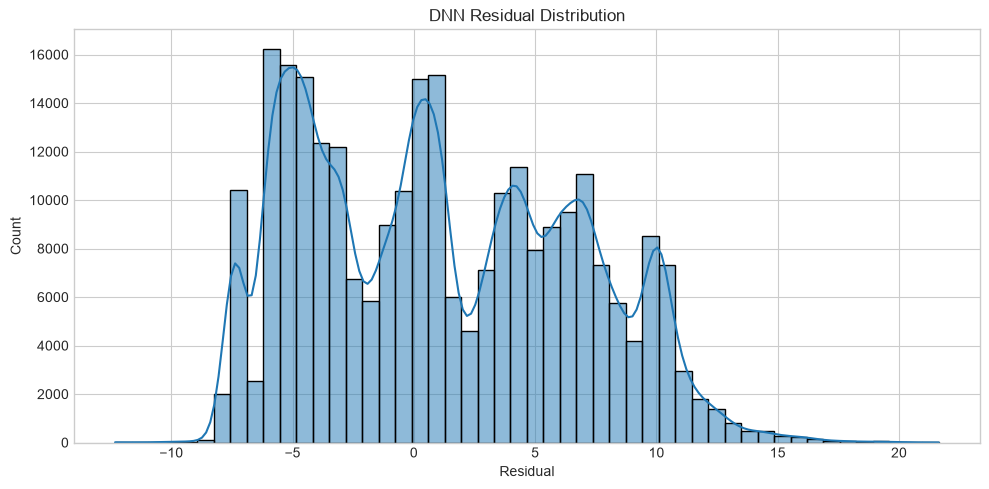

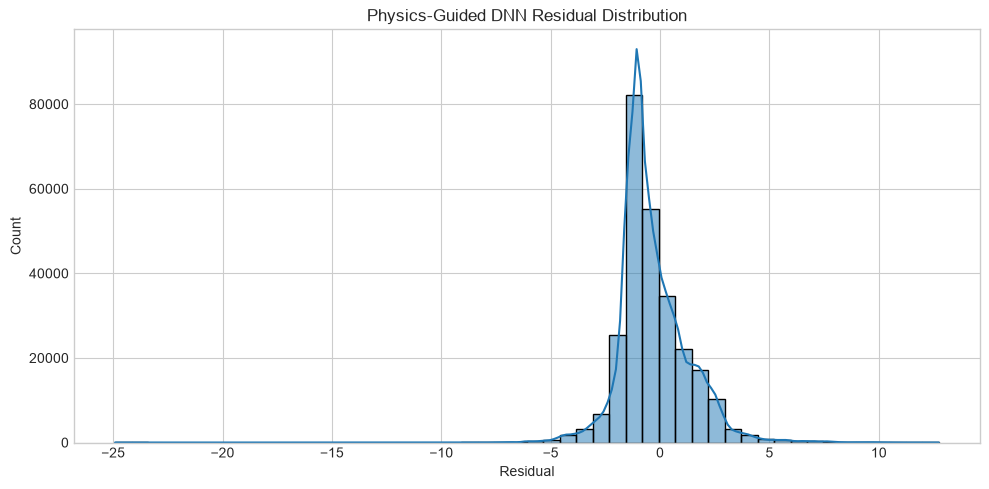

In [85]:
def plot_residual_distribution(y_true, y_pred, title):
    residuals = np.asarray(y_true).reshape(-1) - np.asarray(y_pred).reshape(-1)
    plt.figure(figsize=(10, 5))
    sns.histplot(residuals, bins=50, kde=True)
    plt.title(title)
    plt.xlabel("Residual")
    plt.tight_layout()
    plt.show()

plot_residual_distribution(y_test_true, rf_pred_1d, "Random Forest Residual Distribution")
plot_residual_distribution(y_test_true, dnn_pred_1d, "DNN Residual Distribution")
plot_residual_distribution(y_test_true, pg_pred_1d, "Physics-Guided DNN Residual Distribution")

# Verifyication 

To verify the effectiveness of the proposed approach, the models are evaluated using:

- Mean Absolute Error (MAE)
- Root Mean Squared Error (RMSE)
- Coefficient of Determination ($R^2$)

Consistent improvements across these evaluations would indicate that physics-informed learning provides meaningful benefits for PMSM temperature prediction.


# Additional Visual Diagnostics



,Model,MAE,RMSE,R2
0,Random Forest,1.603222,2.350318,0.994249
1,DNN,4.739132,5.651305,0.966750
2,Physics-Guided DNN,1.246782,1.602132,0.997328
3,Residual PIML,1.171917,1.633593,0.997222


,Model,MAE_vs_RF_%,MAE_vs_DNN_%,RMSE_vs_RF_%,RMSE_vs_DNN_%
0,Physics-Guided DNN,22.232728,73.691772,31.833395,71.650236
1,Residual PIML,26.902381,75.271490,30.494784,71.093522


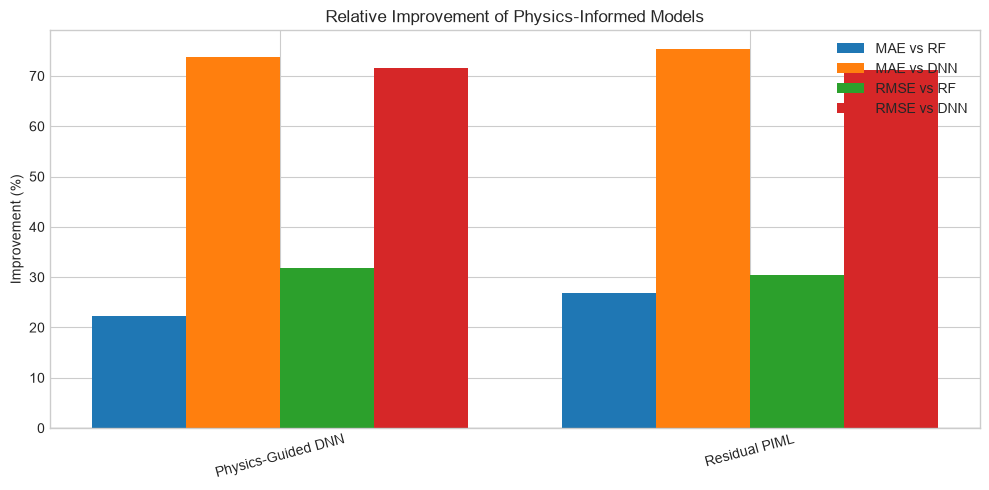

,profile_id,n_samples,RF_MAE,DNN_MAE,PG_MAE,ResidualPIML_MAE
0,2,19357,0.687676,6.900487,1.316871,0.774634
1,6,40388,1.090330,4.065039,1.130928,1.149506
2,12,21942,0.240528,4.088422,0.796588,0.849035
3,14,18598,1.990297,2.521567,0.930157,1.017954
4,20,43971,1.484217,4.534637,1.088132,1.161389
5,26,16666,2.183427,7.420587,0.998167,1.141314
6,43,8443,1.971429,4.228309,1.446282,1.486170
7,45,17142,2.347667,3.777039,1.145536,0.955968
8,56,33123,2.558624,5.504983,1.626203,1.362054
9,59,7475,2.229046,5.775416,2.324659,2.445911


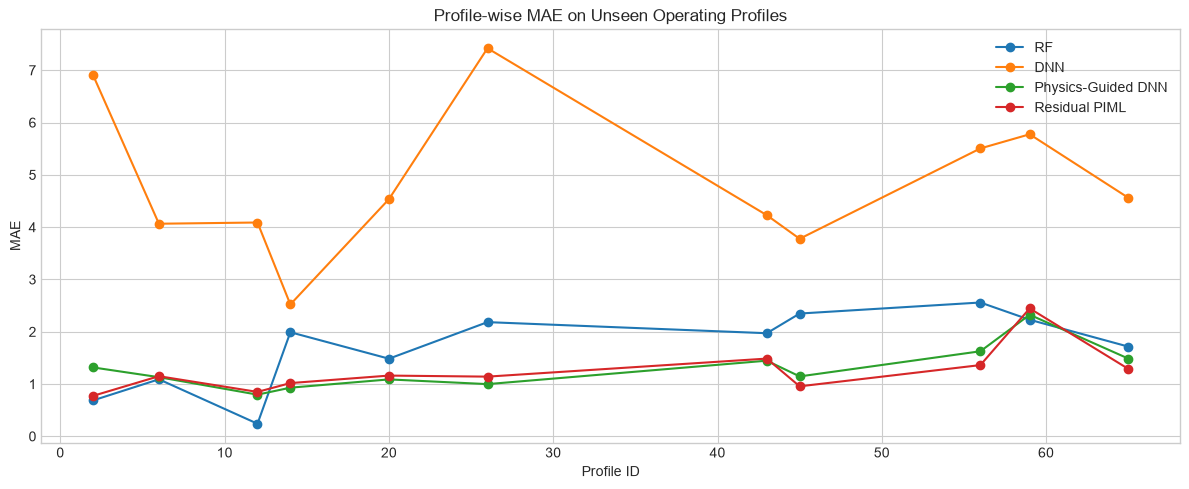

,Regime,Samples,RF_MAE,DNN_MAE,PG_MAE,ResidualPIML_MAE
0,High Current,26720,2.200266,8.069945,1.465825,1.298344
1,High Mechanical Power,26720,1.994822,8.082310,1.341181,1.138628


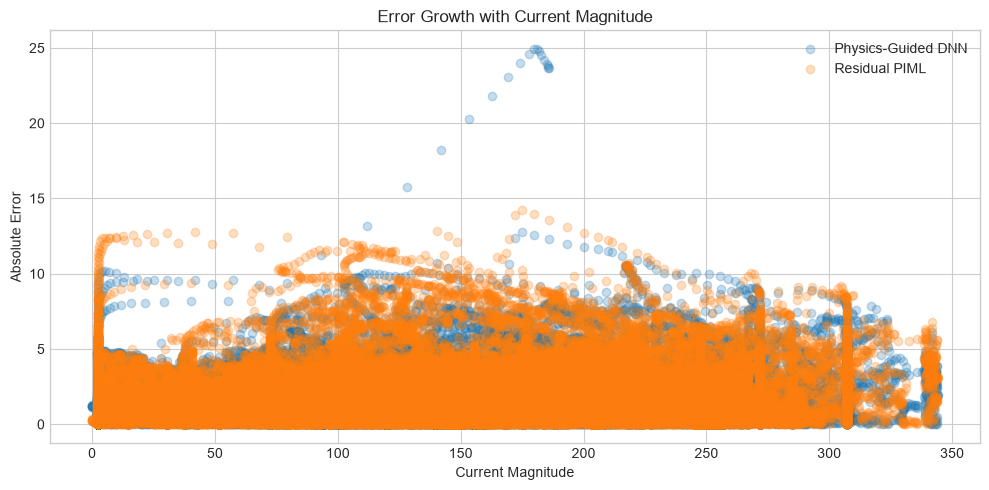

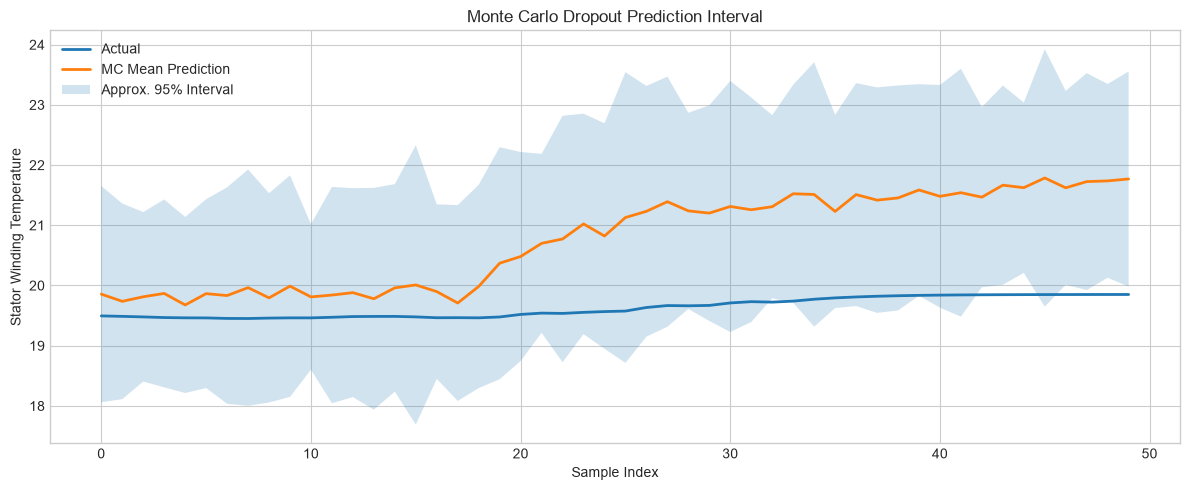

In [87]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# ----------------------------
# Improvement summary
# ----------------------------
def _flatten(a):
    return np.asarray(a).reshape(-1)

model_preds = {
    "Random Forest": rf_pred_1d,
    "DNN": dnn_pred_1d,
    "Physics-Guided DNN": pg_pred_1d,
    "Residual PIML": _flatten(residual_piml_predictions),
}

metric_rows = []
for model_name, preds in model_preds.items():
    metric_rows.append({
        "Model": model_name,
        "MAE": mean_absolute_error(y_test_true, preds),
        "RMSE": np.sqrt(mean_squared_error(y_test_true, preds)),
        "R2": r2_score(y_test_true, preds)
    })

all_models_df = pd.DataFrame(metric_rows)
display(all_models_df)

baseline_mae_rf = all_models_df.loc[all_models_df["Model"]=="Random Forest", "MAE"].iloc[0]
baseline_mae_dnn = all_models_df.loc[all_models_df["Model"]=="DNN", "MAE"].iloc[0]

improvement_rows = []
for model_name in ["Physics-Guided DNN", "Residual PIML"]:
    mae = all_models_df.loc[all_models_df["Model"]==model_name, "MAE"].iloc[0]
    rmse = all_models_df.loc[all_models_df["Model"]==model_name, "RMSE"].iloc[0]
    improvement_rows.append({
        "Model": model_name,
        "MAE_vs_RF_%": 100 * (baseline_mae_rf - mae) / baseline_mae_rf,
        "MAE_vs_DNN_%": 100 * (baseline_mae_dnn - mae) / baseline_mae_dnn,
        "RMSE_vs_RF_%": 100 * (all_models_df.loc[all_models_df["Model"]=="Random Forest", "RMSE"].iloc[0] - rmse) / all_models_df.loc[all_models_df["Model"]=="Random Forest", "RMSE"].iloc[0],
        "RMSE_vs_DNN_%": 100 * (all_models_df.loc[all_models_df["Model"]=="DNN", "RMSE"].iloc[0] - rmse) / all_models_df.loc[all_models_df["Model"]=="DNN", "RMSE"].iloc[0],
    })

improvement_df = pd.DataFrame(improvement_rows)
display(improvement_df)

# ----------------------------
# Percentage improvement plot
# ----------------------------
plt.figure(figsize=(10, 5))
x = np.arange(len(improvement_df["Model"]))
width = 0.2

plt.bar(x - 1.5*width, improvement_df["MAE_vs_RF_%"], width, label="MAE vs RF")
plt.bar(x - 0.5*width, improvement_df["MAE_vs_DNN_%"], width, label="MAE vs DNN")
plt.bar(x + 0.5*width, improvement_df["RMSE_vs_RF_%"], width, label="RMSE vs RF")
plt.bar(x + 1.5*width, improvement_df["RMSE_vs_DNN_%"], width, label="RMSE vs DNN")

plt.xticks(x, improvement_df["Model"], rotation=15)
plt.ylabel("Improvement (%)")
plt.title("Relative Improvement of Physics-Informed Models")
plt.axhline(0, color="black", linewidth=0.8)
plt.legend()
plt.tight_layout()
plt.show()

# ----------------------------
# Profile-wise evaluation
# ----------------------------
profile_eval_rows = []
for pid in sorted(groups_test.unique()):
    idx = (groups_test == pid).to_numpy()
    if idx.sum() < 10:
        continue
    profile_eval_rows.append({
        "profile_id": pid,
        "n_samples": int(idx.sum()),
        "RF_MAE": mean_absolute_error(y_test_true[idx], rf_pred_1d[idx]),
        "DNN_MAE": mean_absolute_error(y_test_true[idx], dnn_pred_1d[idx]),
        "PG_MAE": mean_absolute_error(y_test_true[idx], pg_pred_1d[idx]),
        "ResidualPIML_MAE": mean_absolute_error(y_test_true[idx], _flatten(residual_piml_predictions)[idx]),
    })

profile_eval_df = pd.DataFrame(profile_eval_rows).sort_values("profile_id")
display(profile_eval_df.head(10))

plt.figure(figsize=(12, 5))
plt.plot(profile_eval_df["profile_id"], profile_eval_df["RF_MAE"], marker="o", label="RF")
plt.plot(profile_eval_df["profile_id"], profile_eval_df["DNN_MAE"], marker="o", label="DNN")
plt.plot(profile_eval_df["profile_id"], profile_eval_df["PG_MAE"], marker="o", label="Physics-Guided DNN")
plt.plot(profile_eval_df["profile_id"], profile_eval_df["ResidualPIML_MAE"], marker="o", label="Residual PIML")
plt.xlabel("Profile ID")
plt.ylabel("MAE")
plt.title("Profile-wise MAE on Unseen Operating Profiles")
plt.legend()
plt.tight_layout()
plt.show()

# ----------------------------
# High-load stress test
# ----------------------------
current_q90 = X_test["Current_Magnitude"].quantile(0.90) if "Current_Magnitude" in X_test.columns else np.nan
power_q90 = X_test["Mechanical_Power"].quantile(0.90) if "Mechanical_Power" in X_test.columns else np.nan

if "Current_Magnitude" in X_test.columns:
    high_current_idx = (X_test["Current_Magnitude"] >= current_q90).to_numpy()
else:
    high_current_idx = np.zeros(len(y_test_true), dtype=bool)

if "Mechanical_Power" in X_test.columns:
    high_power_idx = (X_test["Mechanical_Power"] >= power_q90).to_numpy()
else:
    high_power_idx = np.zeros(len(y_test_true), dtype=bool)

stress_rows = []
for name, idx in [("High Current", high_current_idx), ("High Mechanical Power", high_power_idx)]:
    if idx.sum() == 0:
        continue
    stress_rows.append({
        "Regime": name,
        "Samples": int(idx.sum()),
        "RF_MAE": mean_absolute_error(y_test_true[idx], rf_pred_1d[idx]),
        "DNN_MAE": mean_absolute_error(y_test_true[idx], dnn_pred_1d[idx]),
        "PG_MAE": mean_absolute_error(y_test_true[idx], pg_pred_1d[idx]),
        "ResidualPIML_MAE": mean_absolute_error(y_test_true[idx], _flatten(residual_piml_predictions)[idx]),
    })

stress_df = pd.DataFrame(stress_rows)
display(stress_df)

# ----------------------------
# Error versus current magnitude
# ----------------------------
if "Current_Magnitude" in X_test.columns:
    err_pg = np.abs(y_test_true - pg_pred_1d)
    err_res = np.abs(y_test_true - _flatten(residual_piml_predictions))
    plt.figure(figsize=(10, 5))
    plt.scatter(X_test["Current_Magnitude"], err_pg, alpha=0.25, label="Physics-Guided DNN")
    plt.scatter(X_test["Current_Magnitude"], err_res, alpha=0.25, label="Residual PIML")
    plt.xlabel("Current Magnitude")
    plt.ylabel("Absolute Error")
    plt.title("Error Growth with Current Magnitude")
    plt.legend()
    plt.tight_layout()
    plt.show()

# ----------------------------
# Uncertainty interval visualization
# ----------------------------
plot_n = min(50, len(mc_uncertainty_df))
uncertainty_plot = mc_uncertainty_df.head(plot_n).copy()
x_axis = np.arange(plot_n)

plt.figure(figsize=(12, 5))
plt.plot(x_axis, uncertainty_plot["Actual"], label="Actual", linewidth=2)
plt.plot(x_axis, uncertainty_plot["PredictedMean"], label="MC Mean Prediction", linewidth=2)
plt.fill_between(
    x_axis,
    uncertainty_plot["PredictedMean"] - 1.96 * uncertainty_plot["PredStdApprox"],
    uncertainty_plot["PredictedMean"] + 1.96 * uncertainty_plot["PredStdApprox"],
    alpha=0.2,
    label="Approx. 95% Interval"
)
plt.xlabel("Sample Index")
plt.ylabel("Stator Winding Temperature")
plt.title("Monte Carlo Dropout Prediction Interval")
plt.legend()
plt.tight_layout()
plt.show()


In [88]:
def motor_health(temp):

    if temp < 80:
        return "Healthy"

    elif temp < 120:
        return "Warning"

    else:
        return "Critical"

In [89]:
pred_temp = 105

print(
    motor_health(
        pred_temp
    )
)

Warning


In [90]:
sample = {
    "i_d": -90,
    "i_q": 210,
    "u_d": -10,
    "u_q": 320,
    "motor_speed": 3500,
    "torque": 55,
    "coolant": 40
}

In [92]:
import pandas as pd
import torch

# Build a one-row feature table in the same order as the training data
sample_df = pd.DataFrame([sample]).reindex(columns=features, fill_value=0.0)

# Scale the sample with the same scaler used for training
sample_scaled = X_scaler.transform(sample_df)

# Predict with the trained physics-guided model
with torch.no_grad():
    sample_tensor = torch.tensor(sample_scaled, dtype=torch.float32, device=device)
    pred_scaled = pg_model(sample_tensor).cpu().numpy()

# Convert scaled prediction back to real temperature units
pred_temp = y_scaler.inverse_transform(pred_scaled)

print(
    f"Predicted Temperature: {pred_temp[0][0]:.2f} °C"
)
print(
    f"Motor Health Status: {motor_health(pred_temp[0][0])}"
)

Predicted Temperature: 9.22 °C
Motor Health Status: Healthy


# Research Hypothesis

The central hypothesis of this study is that incorporating physical knowledge into the learning process can improve temperature prediction accuracy and generalization.

The expected relationship is:

$$
E_{PIML}
<
E_{RF}
$$

and

$$
E_{PIML}
<
E_{DNN}
$$

where:

- $E_{PIML}$ = Prediction error of the proposed physics-informed model
- $E_{RF}$ = Prediction error of Random Forest
- $E_{DNN}$ = Prediction error of the conventional neural network

The following experiments are designed to test this hypothesis.

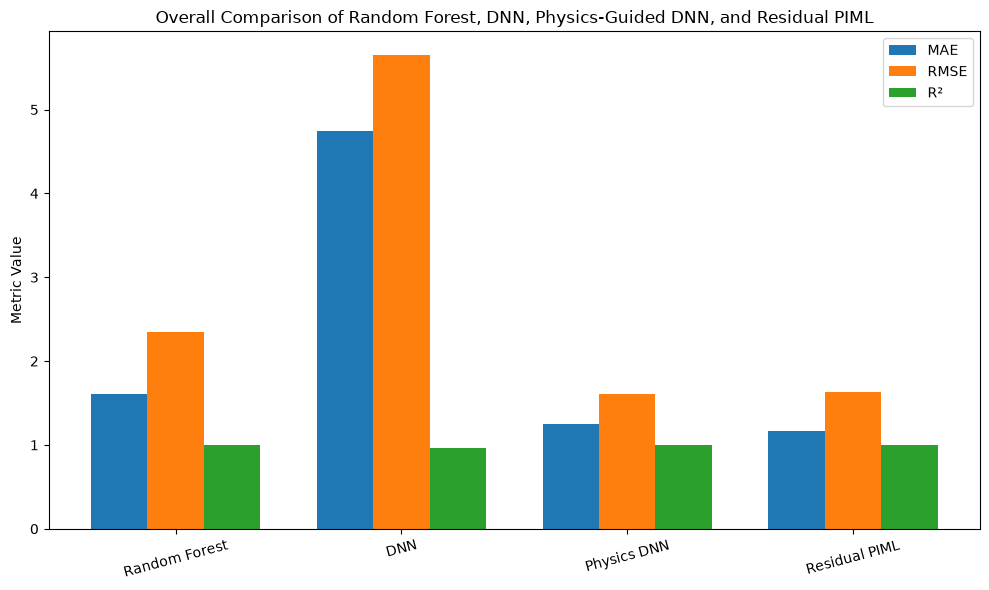

In [4]:
import matplotlib.pyplot as plt
import numpy as np

models = [
    "Random Forest",
    "DNN",
    "Physics DNN",
    "Residual PIML"
]

mae = [1.603, 4.739, 1.247, 1.172]
rmse = [2.350, 5.651, 1.602, 1.634]
r2 = [0.994, 0.967, 0.997, 0.997]

x = np.arange(len(models))
width = 0.25

plt.figure(figsize=(10,6))

plt.bar(x-width, mae, width, label='MAE')
plt.bar(x, rmse, width, label='RMSE')
plt.bar(x+width, r2, width, label='R²')

plt.xticks(x, models, rotation=15)
plt.ylabel("Metric Value")
plt.title("Overall Comparison of Random Forest, DNN, Physics-Guided DNN, and Residual PIML")

plt.legend()
plt.tight_layout()
plt.show()

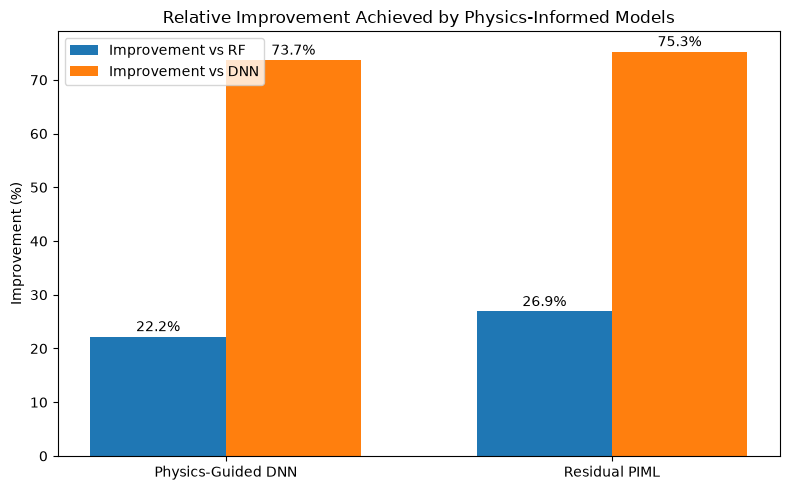

In [6]:
import matplotlib.pyplot as plt
import numpy as np

models = [
    "Physics-Guided DNN",
    "Residual PIML"
]

mae_vs_rf = [22.23, 26.90]
mae_vs_dnn = [73.69, 75.27]

x = np.arange(len(models))
width = 0.35

plt.figure(figsize=(8,5))

plt.bar(
    x - width/2,
    mae_vs_rf,
    width,
    label='Improvement vs RF'
)

plt.bar(
    x + width/2,
    mae_vs_dnn,
    width,
    label='Improvement vs DNN'
)

for i,v in enumerate(mae_vs_rf):
    plt.text(
        i-width/2,
        v+1,
        f"{v:.1f}%",
        ha='center'
    )

for i,v in enumerate(mae_vs_dnn):
    plt.text(
        i+width/2,
        v+1,
        f"{v:.1f}%",
        ha='center'
    )

plt.ylabel("Improvement (%)")
plt.title("Relative Improvement Achieved by Physics-Informed Models")

plt.xticks(x, models)

plt.legend()

plt.tight_layout()


plt.show()

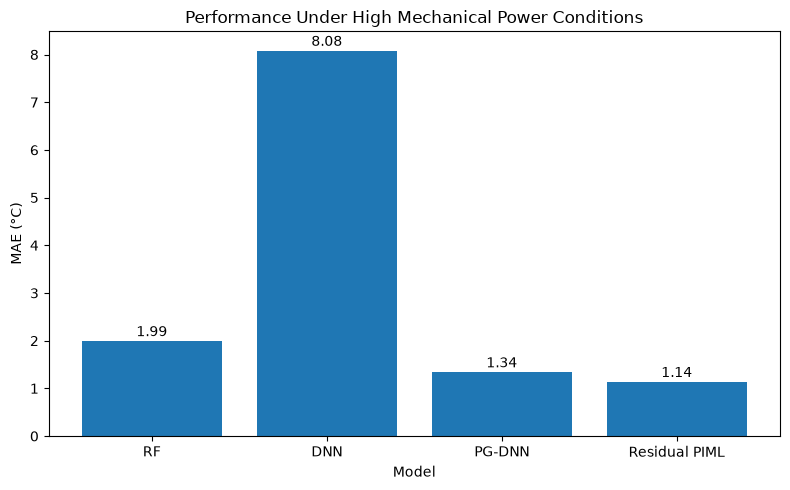

In [8]:
import matplotlib.pyplot as plt

models = [
    "RF",
    "DNN",
    "PG-DNN",
    "Residual PIML"
]

mae = [
    1.994822,
    8.082310,
    1.341181,
    1.138628
]

plt.figure(figsize=(8,5))

bars = plt.bar(models, mae)

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height()+0.1,
        f"{bar.get_height():.2f}",
        ha='center'
    )

plt.ylabel("MAE (°C)")
plt.xlabel("Model")
plt.title("Performance Under High Mechanical Power Conditions")

plt.tight_layout()



plt.show()